# **Tiamat - Previsão de Renda Anual Superior ou Igual a 50 Mil Dólares utilizando Machine Learning** 

Autora: Gabriela O. de Lima Cabral

Professor: Daniel Roberto Cassar

Ilum - Escola de ciência

Centro Nacional de Pesquisa em Energia e Materiais (CNPEM)

## **1. Introdução**

Decisões relacionadas à concessão de crédito, contratação de profissionais, distribuição de benefícios e formulação de políticas públicas dependem, em grande medida, de estimativas sobre a renda da população. Nesse contexto, os censos desempenham um papel fundamental, pois permitem compreender como a renda está distribuída e registram informações demográficas, educacionais e ocupacionais dos indivíduos. A partir desses dados, surge a seguinte questão: é possível prever a faixa de renda de uma pessoa com base em suas características pessoais e profissionais?

Neste trabalho, abordaremos esse problema por meio de técnicas de aprendizado de máquina. Dado um conjunto de atributos de um indivíduo, como idade, escolaridade, ocupação, estado civil, horas trabalhadas por semana e ganhos de capital, será desenvolvido um modelo capaz de prever se sua renda anual é superior a 50 mil dólares. Esse limiar é amplamente utilizado em estudos socioeconômicos e caracteriza uma classe minoritária no conjunto de dados. Como consequência, a distribuição das classes é desbalanceada, tornando a acurácia tradicional uma métrica potencialmente enganosa e justificando o uso da acurácia balanceada como principal medida de avaliação.

O objetivo geral deste trabalho é comparar diferentes algoritmos de aprendizado supervisionado nessa tarefa, realizando ajuste sistemático de hiperparâmetros e avaliando sua capacidade de generalização para dados não vistos. Para isso, serão comparados cinco algoritmos pertencentes a famílias distintas: regressão logística, k-vizinhos mais próximos (KNN), árvore de decisão, floresta aleatória e gradient boosting. Como referência, será utilizado um modelo baseline que sempre prevê a classe majoritária. Os hiperparâmetros de cada algoritmo, bem como etapas de pré-processamento, incluindo normalização de atributos numéricos, codificação de variáveis categóricas e redução de dimensionalidade, serão otimizados por meio da avaliação de 100 configurações distintas para cada método. Posteriormente, será investigado se as diferenças de desempenho observadas são estatisticamente significativas por meio de validação cruzada repetida. Por fim, o modelo selecionado será avaliado uma única vez em um conjunto de teste reservado desde o início do estudo, verificando sua capacidade de capturar padrões reais dos dados e analisando a uniformidade de desempenho entre diferentes grupos de sexo e raça.

# 2. Bibliotecas e configurações prévias

Todas as etapas com aleatoriedade usam a semente 24. As versões das bibliotecas estão fixadas em `requirements.txt`, para que o resultado possa ser reproduzido.

In [319]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import optuna
import shap
import sklearn
from scipy import stats
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectPercentile, f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, brier_score_loss, confusion_matrix,
    f1_score, log_loss, make_scorer, matthews_corrcoef, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import (
    StratifiedGroupKFold, cross_val_predict, cross_validate, train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer, MinMaxScaler, OneHotEncoder, OrdinalEncoder, StandardScaler,
)
from sklearn.tree import DecisionTreeClassifier

In [320]:
import os

# Silencia avisos esperados (ex.: categorias raras agrupadas) também nos processos filhos do joblib.
os.environ["PYTHONWARNINGS"] = "ignore"

import time
import warnings
from functools import partial 

warnings.filterwarnings("ignore", category=optuna.exceptions.ExperimentalWarning)
warnings.filterwarnings("ignore", message=".*unknown categories.*")
warnings.filterwarnings("ignore", message=".*are constant.*")
optuna.logging.set_verbosity(optuna.logging.WARNING)

Na célula abaixo, são definidos alguns parâmetros gerais: o valor da semente que controla a aleatoriedade e garante a reprodutibiliade; a porcentagem dos dados que serão utlizados para teste; a quantidade de linhas que será usada durante a busca de hiperparâmetros a fim de acelerar os resultados com o Optuna e por fim o número de configurações que serão testadas. 

In [321]:
SEMENTE = 24
TAMANHO_TESTE = 0.2
NUM_FOLDS = 5                
NUM_TENTATIVAS = 100        

Dando seguimento, indica-se o caminho do arquivo contendo os dados utilizados no estudo. Além disso, são definidas manualmente as colunas presentes no conjunto de dados Adult Census Income, permitindo que o arquivo seja carregado corretamente e que cada atributo seja identificado pelo seu respectivo nome durante as etapas posteriores

In [322]:
CAMINHO_DADOS = "adult.data"
PASTA_ESTUDOS = "estudos"

COLUNAS = [
    "age", "workclass", "fnlwgt", "education", "educational-num", "marital-status",
    "occupation", "relationship", "race", "gender", "capital-gain", "capital-loss",
    "hours-per-week", "native-country", "income",
]

ATRIBUTOS_NUMERICOS = ["age", "educational-num", "capital-gain", "capital-loss", "hours-per-week"]
ATRIBUTOS_CATEGORICOS = ["workclass", "education", "marital-status", "occupation", "relationship",
                         "race", "gender", "native-country"]
ATRIBUTOS = ATRIBUTOS_NUMERICOS + ATRIBUTOS_CATEGORICOS  
NOME_ALVO = "income"
NOME_ALVO_BINARIO = "rendimento_acima_50k"

DESCRICOES = {
    "age": "Idade em anos",
    "educational-num": "Anos de estudo (escala numérica do censo)",
    "capital-gain": "Ganho de capital no ano (dólares)",
    "capital-loss": "Perda de capital no ano (dólares)",
    "hours-per-week": "Horas trabalhadas por semana",
    "workclass": "Tipo de vínculo de trabalho (privado, público, autônomo etc.)",
    "education": "Nível de escolaridade (categórico)",
    "marital-status": "Estado civil",
    "occupation": "Ocupação",
    "relationship": "Papel na família (esposo, filho, não aparentado etc.)",
    "race": "Raça autodeclarada",
    "gender": "Sexo (male/female, conforme o censo)",
    "native-country": "País de origem",
}

## 3. O conjunto de dados

O conjunto de dados utilizado é o Adult, também conhecido como Census Income, disponível no UCI Machine Learning Repository e derivado de uma extração da Current Population Survey de 1994. O arquivo de treino original tem 32.561 registros, dos quais 30.139 permanecem após a remoção de valores ausentes e de duplicatas exatas. Cada registro traz 13 atributos utilizados pelo modelo, cinco numéricos e oito categóricos. O peso amostral do censo, `fnlwgt`, foi deliberadamente excluído, porque descreve a representatividade do registro na população e não uma característica da pessoa. Esse conjunto é amplamente estudado, o que permite comparar os resultados com a literatura, e reúne atributos mistos, valores ausentes e forte assimetria, o que aproxima o trabalho de situações reais. Ao mesmo tempo, é um conjunto antigo: os registros refletem o mercado de trabalho e a estrutura social dos Estados Unidos de 1994, e não devem ser lidos como retrato do presente.

O arquivo usado neste projeto é o **`adult.data`**, com **32.561 registros**.Cada registro descreve uma pessoa por 14 atributos e pela renda anual, que é o alvo. O UCI traz também o arquivo `adult.test` com 16.281 registros, ele não é usado aqui, porque a divisão treino/teste do projeto é feita a partir do `adult.data`, de forma organizada e controlada pela semente.

### 3.1 Dicionário dos atributos

| Atributo | Tipo | Descrição |
|---|---|---|
| `age` | numérico | Idade em anos |
| `workclass` | categórico | Tipo de vínculo de trabalho |
| `fnlwgt` | numérico | Peso amostral do censo (não é usado como atributo) |
| `education` | categórico | Nível de escolaridade |
| `educational-num` | numérico | Anos de estudo |
| `marital-status` | categórico | Estado civil |
| `occupation` | categórico | Ocupação |
| `relationship` | categórico | Papel na família |
| `race` | categórico | Raça autodeclarada |
| `gender` | categórico | Sexo |
| `capital-gain` | numérico | Ganho de capital no ano |
| `capital-loss` | numérico | Perda de capital no ano |
| `hours-per-week` | numérico | Horas trabalhadas por semana |
| `native-country` | categórico | País de origem |
| `income` | alvo | `>50K` ou `<=50K` |

Os valores ausentes aparecem como `?` e ocorrem em `workclass`, `occupation` e `native-country`. A classe positiva, renda acima de 50 mil dólares, é minoritária, com cerca de um quarto dos registros.

Os atributos `education` e `educational-num` trazem a mesma informação, de formas diferentes. Isso é importante na interpretação, como se verá na seção de resultados.

In [323]:
COLUNAS = [
    "age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
    "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
    "hours-per-week", "native-country", "income",
]

df_bruto = pd.read_csv(
    CAMINHO_DADOS, header=None, names=COLUNAS, skipinitialspace=True, na_values="?"
)

print(f"Formato: {df_bruto.shape[0]} linhas × {df_bruto.shape[1]} colunas")
df_bruto.head()

Formato: 32561 linhas × 15 colunas


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [324]:
df_bruto.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


### 3.2 Dados faltantes e duplicatas

Três colunas categóricas têm valores ausentes (marcados com `?` no arquivo original). Como veremos na EDA, o fato de a informação estar ausente pode ele próprio ser informativo, então **não vamos descartar essas linhas**: dentro do pipeline, os ausentes serão tratados como uma categoria própria chamada `Desconhecido`. Fazer isso dentro do pipeline é uma conversão sem estágio de ajuste, mas mantê-la lá garante que o mesmo tratamento seja aplicado a qualquer dado novo.

In [325]:
faltantes = df_bruto.isna().sum()
faltantes = faltantes[faltantes > 0].to_frame("n_faltantes")
faltantes["% do total"] = (100 * faltantes["n_faltantes"] / len(df_bruto)).round(2)
display(faltantes)

print("Linhas totalmente duplicadas (todas as 15 colunas):", df_bruto.duplicated().sum())

,n_faltantes,% do total
workclass,1836,5.64
occupation,1843,5.66
native-country,583,1.79


Linhas totalmente duplicadas (todas as 15 colunas): 24


### 3.3 Duas decisões sobre colunas (antes de qualquer modelagem)

**(a) `education` é redundante com `education-num`.** Cada nível de escolaridade em texto corresponde a exatamente um número, e vice-versa. Manter as duas colunas só adicionaria colinearidade perfeita (e dezenas de colunas *one-hot* redundantes). Ficamos com `education-num`, que já está em escala ordinal e preserva a ordem dos níveis.

**(b) `fnlwgt` não é uma característica da pessoa.** Ele é um peso de amostragem calculado pelo censo para que a amostra represente a população; ele descreve o *desenho amostral*, não o indivíduo. Incluí-lo em um modelo preditivo de renda não faz sentido causal (não é um atributo que *cause* a renda) e, na prática, adiciona uma coluna numérica quase única por linha, que só serve para o modelo memorizar exemplos. Por isso, **removemos `fnlwgt`**. (Na Seção 5.6 conferimos, apenas com dados de treino, que ele não carrega informação sobre o target.)

In [326]:

n_edu_por_num = df_bruto.groupby("education-num")["education"].nunique().max()
n_num_por_edu = df_bruto.groupby("education")["education-num"].nunique().max()
print(f"Máx. de textos de 'education' por valor de 'education-num': {n_edu_por_num}")
print(f"Máx. de valores de 'education-num' por texto de 'education': {n_num_por_edu}")

COLUNAS_REMOVIDAS = ["fnlwgt", "education"]
ATRIBUTOS_NUMERICOS = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
ATRIBUTOS_CATEGORICOS = ["workclass", "marital-status", "occupation", "relationship",
                         "race", "sex", "native-country"]
ATRIBUTOS = ATRIBUTOS_NUMERICOS + ATRIBUTOS_CATEGORICOS

X_total = df_bruto.reindex(ATRIBUTOS, axis=1)
y_total = (df_bruto["income"] == ">50K").astype(int)   # 1 = renda > 50K (classe positiva)

print(f"\nAtributos usados: {len(ATRIBUTOS)} ({len(ATRIBUTOS_NUMERICOS)} numéricos + "
      f"{len(ATRIBUTOS_CATEGORICOS)} categóricos)")

Máx. de textos de 'education' por valor de 'education-num': 1
Máx. de valores de 'education-num' por texto de 'education': 1

Atributos usados: 12 (5 numéricos + 7 categóricos)


In [327]:
ROTULOS = {
    "age": "Idade (anos)", "education-num": "Escolaridade (níveis)",
    "capital-gain": "Ganho de capital (US$)", "capital-loss": "Perda de capital (US$)",
    "hours-per-week": "Horas trabalhadas por semana", "workclass": "Classe de trabalho",
    "marital-status": "Estado civil", "occupation": "Ocupação", "relationship": "Papel na família",
    "race": "Raça", "sex": "Sexo", "native-country": "País de origem",
}

## 4. Divisão treino/teste sem vazamento de dados

### 4.1 Por que não basta um `train_test_split` aleatório?

Como discutido na aula sobre vazamento de dados, se dois exemplos **redundantes ou quase redundantes** caem um no treino e outro no teste, o modelo "já viu" a resposta de parte do teste, e as métricas ficam **infladas**. É a analogia do professor que cobra na prova os mesmos exercícios da lista.

No Adult isso é um risco real: depois de remover `fnlwgt`, há **milhares de linhas com exatamente os mesmos valores em todos os atributos** (pessoas diferentes com o mesmo perfil). Além disso, há muitos perfis *quase* idênticos (por exemplo, duas pessoas iguais em tudo, com 40 e 41 anos).

### 4.2 Estratégia: grupos de exemplos quase redundantes + divisão agrupada e estratificada

1.  Arredondamos os atributos numéricos *apenas para identificar grupos* (idade e horas semanais para múltiplos de 5; ganho e perda de capital para milhares de dólares). Exemplos que têm os mesmos valores arredondados e as mesmas categorias pertencem ao **mesmo grupo**.
2.  Dividimos com o `StratifiedGroupKFold`: ele **nunca separa um grupo** entre treino e teste (evitando o vazamento) e, ao mesmo tempo, **preserva a proporção das classes** (estratificação). Usamos o primeiro dos 5 folds como teste, o que dá ~20% dos dados.
3. Os dados finais são os **valores originais**, sem arredondamento (o arredondamento só serviu para formar os grupos).


In [328]:
def cria_grupos(X):
    X_arred = X.copy()
    X_arred["age"] = (X["age"] / 5).round() * 5
    X_arred["hours-per-week"] = (X["hours-per-week"] / 5).round() * 5
    X_arred["capital-gain"] = X["capital-gain"].round(-3)
    X_arred["capital-loss"] = X["capital-loss"].round(-3)
    return X_arred.groupby(list(X.columns), dropna=False).ngroup().to_numpy()


grupos_total = cria_grupos(X_total)
tamanho_grupos = pd.Series(grupos_total).value_counts()

print(f"Exemplos: {len(X_total)}")
print(f"Grupos distintos: {tamanho_grupos.size}")
print(f"Maior grupo: {tamanho_grupos.max()} exemplos")
print(f"Exemplos que pertencem a grupos com mais de 1 membro: "
      f"{(tamanho_grupos[tamanho_grupos > 1].sum() / len(X_total)):.1%}")

Exemplos: 32561
Grupos distintos: 23338
Maior grupo: 78 exemplos
Exemplos que pertencem a grupos com mais de 1 membro: 38.8%


In [329]:
divisor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
indices_treino, indices_teste = next(divisor.split(X_total, y_total, groups=grupos_total))

X_treino = X_total.iloc[indices_treino].reset_index(drop=True)
y_treino = y_total.iloc[indices_treino].reset_index(drop=True)
grupos_treino = grupos_total[indices_treino]

X_teste = X_total.iloc[indices_teste].reset_index(drop=True)
y_teste = y_total.iloc[indices_teste].reset_index(drop=True)
grupos_teste = grupos_total[indices_teste]

assert set(grupos_treino).isdisjoint(set(grupos_teste)), "Há grupos nos dois conjuntos!"

resumo_split = pd.DataFrame({
    "n exemplos": [len(X_treino), len(X_teste)],
    "% do total": [len(X_treino) / len(X_total) * 100, len(X_teste) / len(X_total) * 100],
    "% com renda > 50K": [y_treino.mean() * 100, y_teste.mean() * 100],
}, index=["Treino", "Teste"]).round(2)
resumo_split

,n exemplos,% do total,% com renda > 50K
Treino,26112,80.19,24.15
Teste,6449,19.81,23.79


### 4.3 Checando a saúde do split

Como no notebook de vazamento de dados, vamos comparar duas distribuições da **menor distância Manhattan** (em dados normalizados por mínimos e máximos, com o normalizador **ajustado só no treino**):

-   **treino × treino**: para cada exemplo de treino, a distância até o exemplo de treino mais próximo (diferente dele mesmo);
-   **treino × teste**: para cada exemplo de teste, a distância até o exemplo de treino mais próximo.

Se o split for saudável, os exemplos de teste devem estar **mais longe** do treino do que os exemplos de treino estão uns dos outros (pois não há "gêmeos" cruzando a fronteira). Usamos o teste de Mann-Whitney com a hipótese alternativa de que as distâncias treino×treino são *menores* que as treino×teste; **rejeitar H0 indica split saudável**.

Para comparar, repetimos o procedimento com um split **ingênuo** (`train_test_split` estratificado, sem considerar grupos). Para economizar tempo, as distâncias treino×treino são calculadas para uma amostra de 5.000 exemplos de treino (cada um buscando seu vizinho mais próximo entre *todos* os demais exemplos de treino).

In [330]:
def distancias_minimas(X_tr, X_te, tamanho_amostra=5000):
    """Menores distâncias Manhattan treino×treino e treino×teste."""
    prep = ColumnTransformer([
        ("num", MinMaxScaler(), ATRIBUTOS_NUMERICOS),
        ("cat", make_cat_pipeline(), ATRIBUTOS_CATEGORICOS),
    ])
    A_tr = prep.fit_transform(X_tr)      # ajustado SOMENTE no treino
    A_te = prep.transform(X_te)

    vizinhos = NearestNeighbors(n_neighbors=2, metric="manhattan", algorithm="brute", n_jobs=-1)
    vizinhos.fit(A_tr)

    rng = np.random.default_rng(SEMENTE)
    amostra = rng.choice(len(A_tr), size=min(tamanho_amostra, len(A_tr)), replace=False)

    treino_treino = vizinhos.kneighbors(A_tr[amostra])[0][:, 1]
    treino_teste = vizinhos.kneighbors(A_te, n_neighbors=1)[0][:, 0]
    return treino_treino, treino_teste


def make_cat_pipeline():
    return Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
        ("oh", OneHotEncoder(handle_unknown="ignore", drop="if_binary", sparse_output=False)),
    ])


idx_tr_ing, idx_te_ing = train_test_split(
    np.arange(len(X_total)), test_size=TAMANHO_TESTE, random_state=SEMENTE,
    stratify=y_total,
)

d_agrupado = distancias_minimas(X_treino, X_teste)
d_ingenuo = distancias_minimas(X_total.iloc[idx_tr_ing], X_total.iloc[idx_te_ing])

Split agrupado (usado neste trabalho): p-valor = 5.218e-55 | % de exemplos de teste com um 'gêmeo' idêntico no treino: 0.0%
Split ingênuo (aleatório): p-valor = 1.383e-01 | % de exemplos de teste com um 'gêmeo' idêntico no treino: 16.9%


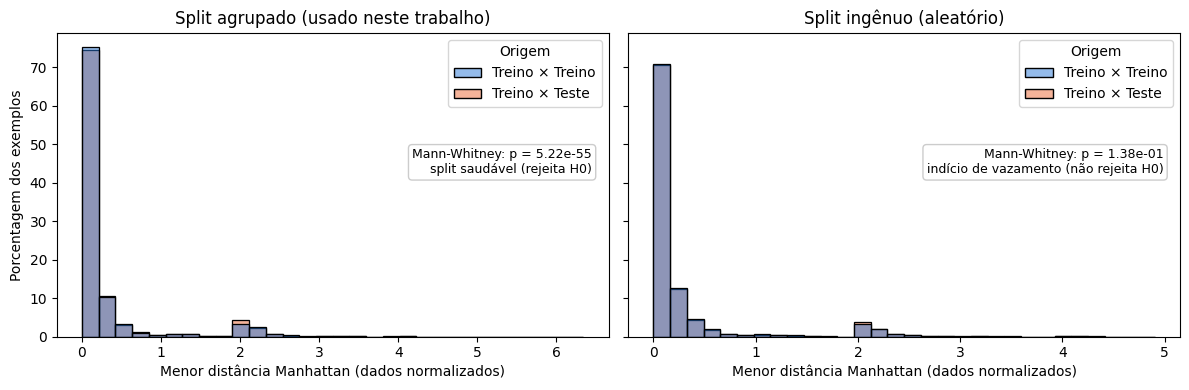

In [331]:
NIVEL_CONFIANCA = 0.95
fig, eixos = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for eixo, (titulo, (d_tt, d_te)) in zip(
    eixos, [("Split agrupado (usado neste trabalho)", d_agrupado), ("Split ingênuo (aleatório)", d_ingenuo)]
):
    dist = pd.concat([
        pd.DataFrame({"valor": d_tt, "Origem": "Treino × Treino"}),
        pd.DataFrame({"valor": d_te, "Origem": "Treino × Teste"}),
    ], ignore_index=True)
    bins = np.histogram_bin_edges(dist["valor"], bins=30)
    sns.histplot(data=dist, x="valor", hue="Origem", bins=bins, alpha=0.5, stat="percent",
                 common_norm=False, ax=eixo, palette={"Treino × Treino": "#2a78d6", "Treino × Teste": "#eb6834"})
    eixo.set(title=titulo, xlabel="Menor distância Manhattan (dados normalizados)", ylabel="Porcentagem dos exemplos")
    p_valor = stats.mannwhitneyu(d_tt, d_te, alternative="less").pvalue
    veredito = "split saudável (rejeita H0)" if p_valor < 1 - NIVEL_CONFIANCA else "indício de vazamento (não rejeita H0)"
    eixo.text(0.97, 0.62, f"Mann-Whitney: p = {p_valor:.2e}\n{veredito}", transform=eixo.transAxes,
              ha="right", va="top", fontsize=9, bbox=dict(boxstyle="round", fc="white", ec="#cccccc"))
    print(f"{titulo}: p-valor = {p_valor:.3e} | % de exemplos de teste com um 'gêmeo' idêntico no treino: "
          f"{(d_te == 0).mean():.1%}")
plt.tight_layout()
plt.show()

**Leitura do resultado.** No split ingênuo, uma grande fração dos exemplos de teste tem um "gêmeo" a distância zero no treino, e o teste de hipótese **não** rejeita H0: o split vaza informação. No split agrupado, a distância mínima entre teste e treino é maior que a distância entre exemplos do próprio treino, e o teste rejeita H0, isto é, o split é saudável. Os números exatos estão impressos acima (percentuais de "gêmeos" e p-valores).

A partir daqui, **o conjunto de teste fica guardado**. Nada é ajustado nem escolhido com ele até a Seção 10.

## 5. Análise exploratória dos dados (somente treino)

Para evitar qualquer "espiada" no conjunto de teste, **toda a análise exploratória usa apenas os dados de treino**. O objetivo é entender o problema e embasar as decisões de pré-processamento e modelagem.

In [332]:
df_eda = X_treino.copy()
df_eda["renda"] = np.where(y_treino == 1, "> 50K", "≤ 50K")
df_eda["alvo"] = y_treino.values
print(f"Linhas de treino na EDA: {len(df_eda)}")

Linhas de treino na EDA: 26112


### 5.1 O target: classes desbalanceadas

Apenas cerca de um quarto das pessoas ganha mais de US$ 50 mil. Isso tem uma consequência prática imediata: **um classificador que sempre responde "≤ 50K" já acerta cerca de 76%**. Acurácia, portanto, não é uma boa métrica aqui (era o exemplo da doença rara na aula de métricas). Voltamos a isso na Seção 6.

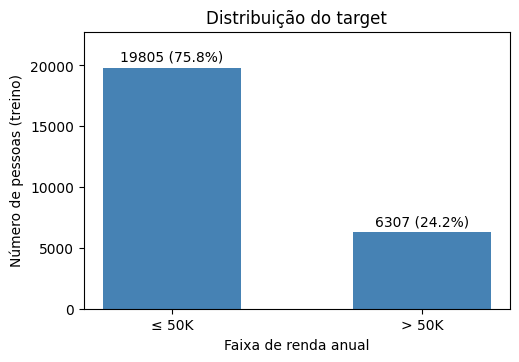

In [333]:
contagem = df_eda["renda"].value_counts().reindex(["≤ 50K", "> 50K"])

fig, eixo = plt.subplots(figsize=(5.5, 3.6))
eixo.bar(contagem.index, contagem.values,
         color="steelblue",
         width=0.55)
for i, v in enumerate(contagem.values):
    eixo.text(i, v + 300, f"{v} ({v / len(df_eda):.1%})", ha="center", va="bottom")
eixo.set(xlabel="Faixa de renda anual", ylabel="Número de pessoas (treino)", title="Distribuição do target")
eixo.set_ylim(0, contagem.max() * 1.15)
plt.show()

### 5.2 Atributos numéricos

Observações a procurar: escalas muito diferentes (importante para algoritmos sensíveis a distância e a regularização), assimetrias e valores atípicos.

In [334]:
display(X_treino[ATRIBUTOS_NUMERICOS].describe().T.round(2))

pct_gain = (X_treino["capital-gain"] == 0).mean()
pct_loss = (X_treino["capital-loss"] == 0).mean()
print(f"\n% de pessoas com ganho de capital igual a zero: {pct_gain:.1%}")
print(f"% de pessoas com perda de capital igual a zero: {pct_loss:.1%}")
print(f"Assimetria (skewness) de capital-gain: {stats.skew(X_treino['capital-gain']):.1f} | "
      f"de capital-loss: {stats.skew(X_treino['capital-loss']):.1f} | de age: {stats.skew(X_treino['age']):.2f}")

,count,mean,std,min,25%,50%,75%,max
age,26112.0,38.66,13.67,17.0,28.0,37.0,48.0,90.0
education-num,26112.0,10.07,2.57,1.0,9.0,10.0,12.0,16.0
capital-gain,26112.0,1066.28,7273.70,0.0,0.0,0.0,0.0,99999.0
capital-loss,26112.0,87.00,403.16,0.0,0.0,0.0,0.0,4356.0
hours-per-week,26112.0,40.37,12.32,1.0,40.0,40.0,45.0,99.0



% de pessoas com ganho de capital igual a zero: 91.6%
% de pessoas com perda de capital igual a zero: 95.4%
Assimetria (skewness) de capital-gain: 12.1 | de capital-loss: 4.6 | de age: 0.54


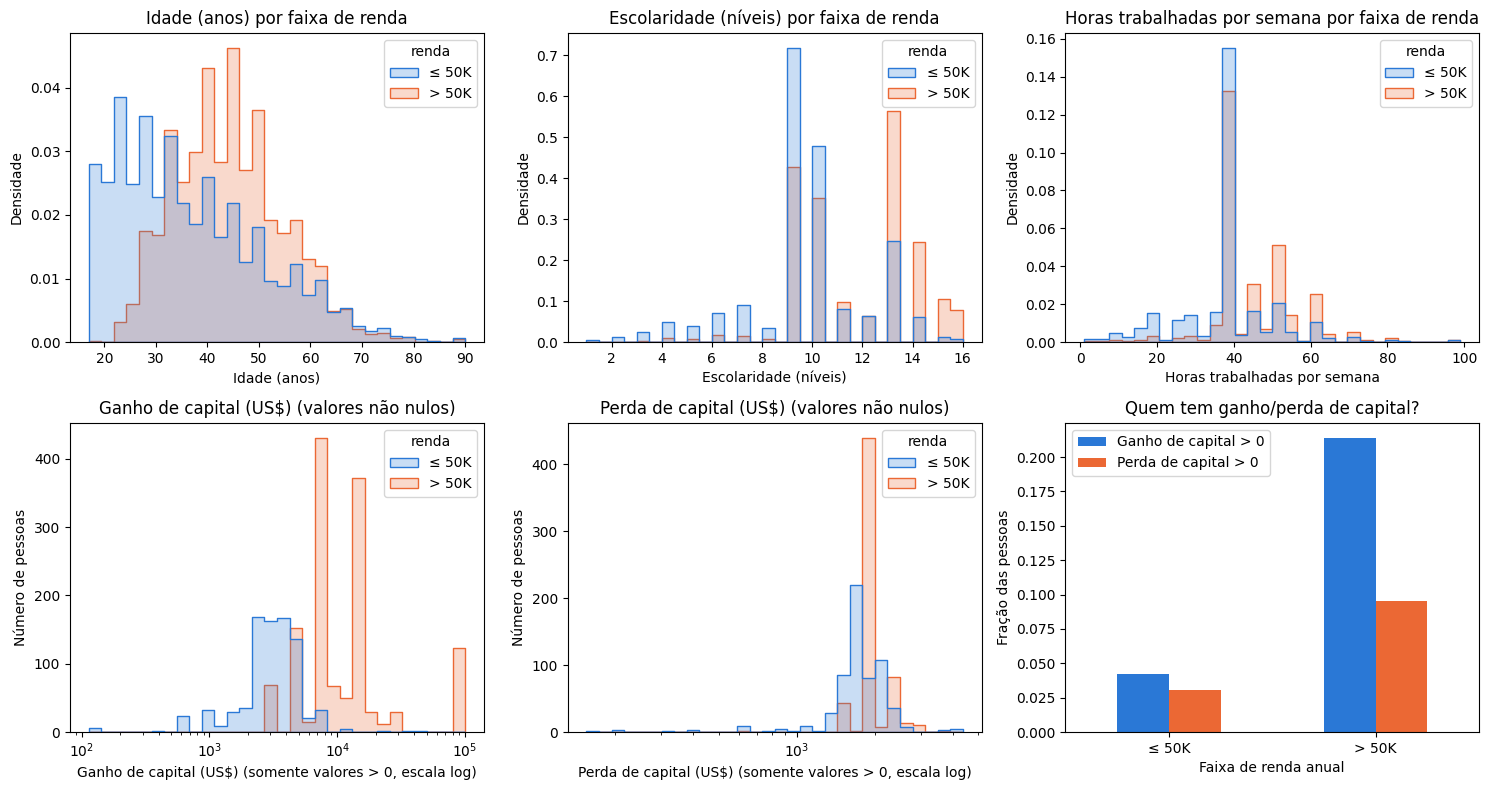

In [335]:
fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
eixos = eixos.ravel()

COR_CLASSE = {"≤ 50K": "#2a78d6", "> 50K": "#eb6834"}    

for eixo, coluna in zip(eixos[:3], ["age", "education-num", "hours-per-week"]):
    sns.histplot(data=df_eda, x=coluna, hue="renda", stat="density", common_norm=False,
                 element="step", bins=30, palette=COR_CLASSE, ax=eixo, hue_order=["≤ 50K", "> 50K"])
    eixo.set(xlabel=ROTULOS[coluna], ylabel="Densidade", title=ROTULOS[coluna] + " por faixa de renda")

for eixo, coluna in zip(eixos[3:5], ["capital-gain", "capital-loss"]):
    nao_nulos = df_eda[df_eda[coluna] > 0]
    sns.histplot(data=nao_nulos, x=coluna, hue="renda", stat="count", element="step", bins=30,
                 log_scale=True, palette=COR_CLASSE, ax=eixo, hue_order=["≤ 50K", "> 50K"])
    eixo.set(xlabel=ROTULOS[coluna] + " (somente valores > 0, escala log)", ylabel="Número de pessoas",
             title=ROTULOS[coluna] + " (valores não nulos)")

frac = pd.DataFrame({
    "Ganho de capital > 0": df_eda.groupby("renda")["capital-gain"].apply(lambda s: (s > 0).mean()),
    "Perda de capital > 0": df_eda.groupby("renda")["capital-loss"].apply(lambda s: (s > 0).mean()),
}).reindex(["≤ 50K", "> 50K"])
frac.plot.bar(ax=eixos[5], color=["#2a78d6", "#eb6834"], rot=0)
eixos[5].set(xlabel="Faixa de renda anual", ylabel="Fração das pessoas",
             title="Quem tem ganho/perda de capital?")
eixos[5].legend(title="")
plt.tight_layout()
plt.show()

**O que vemos.**

-   `age`, `education-num` e `hours-per-week` têm distribuições distintas entre as classes: quem ganha mais de US$ 50 mil tende a ser mais velho, mais escolarizado e a trabalhar mais horas, embora haja muita sobreposição.
-   `capital-gain` e `capital-loss` são **dominados por zeros** e, quando não nulos, variam por ordens de grandeza (distribuição extremamente assimétrica). Ter ganho de capital > 0 é muito mais comum entre quem ganha mais de US$ 50 mil.
-   As escalas dos atributos são muito diferentes (idade na casa das dezenas; ganho de capital até dezenas de milhares). Isso **exige normalização** para modelos sensíveis a distância (*k*-NN), à regularização (regressão logística) e para o PCA. Para os ganhos e perdas de capital, aplicaremos antes um `log(1 + x)`, que não tem etapa de ajuste (logo não causa vazamento) e comprime a cauda longa.

### 5.3 Atributos categóricos e a taxa de renda > 50K

Para cada categoria, mostramos a **proporção de pessoas com renda > 50K** (barra) e o **número de pessoas** (texto). A linha vertical tracejada é a taxa geral do treino. Categorias com poucas pessoas têm taxas pouco confiáveis; para `native-country` mostramos só as 10 mais frequentes.

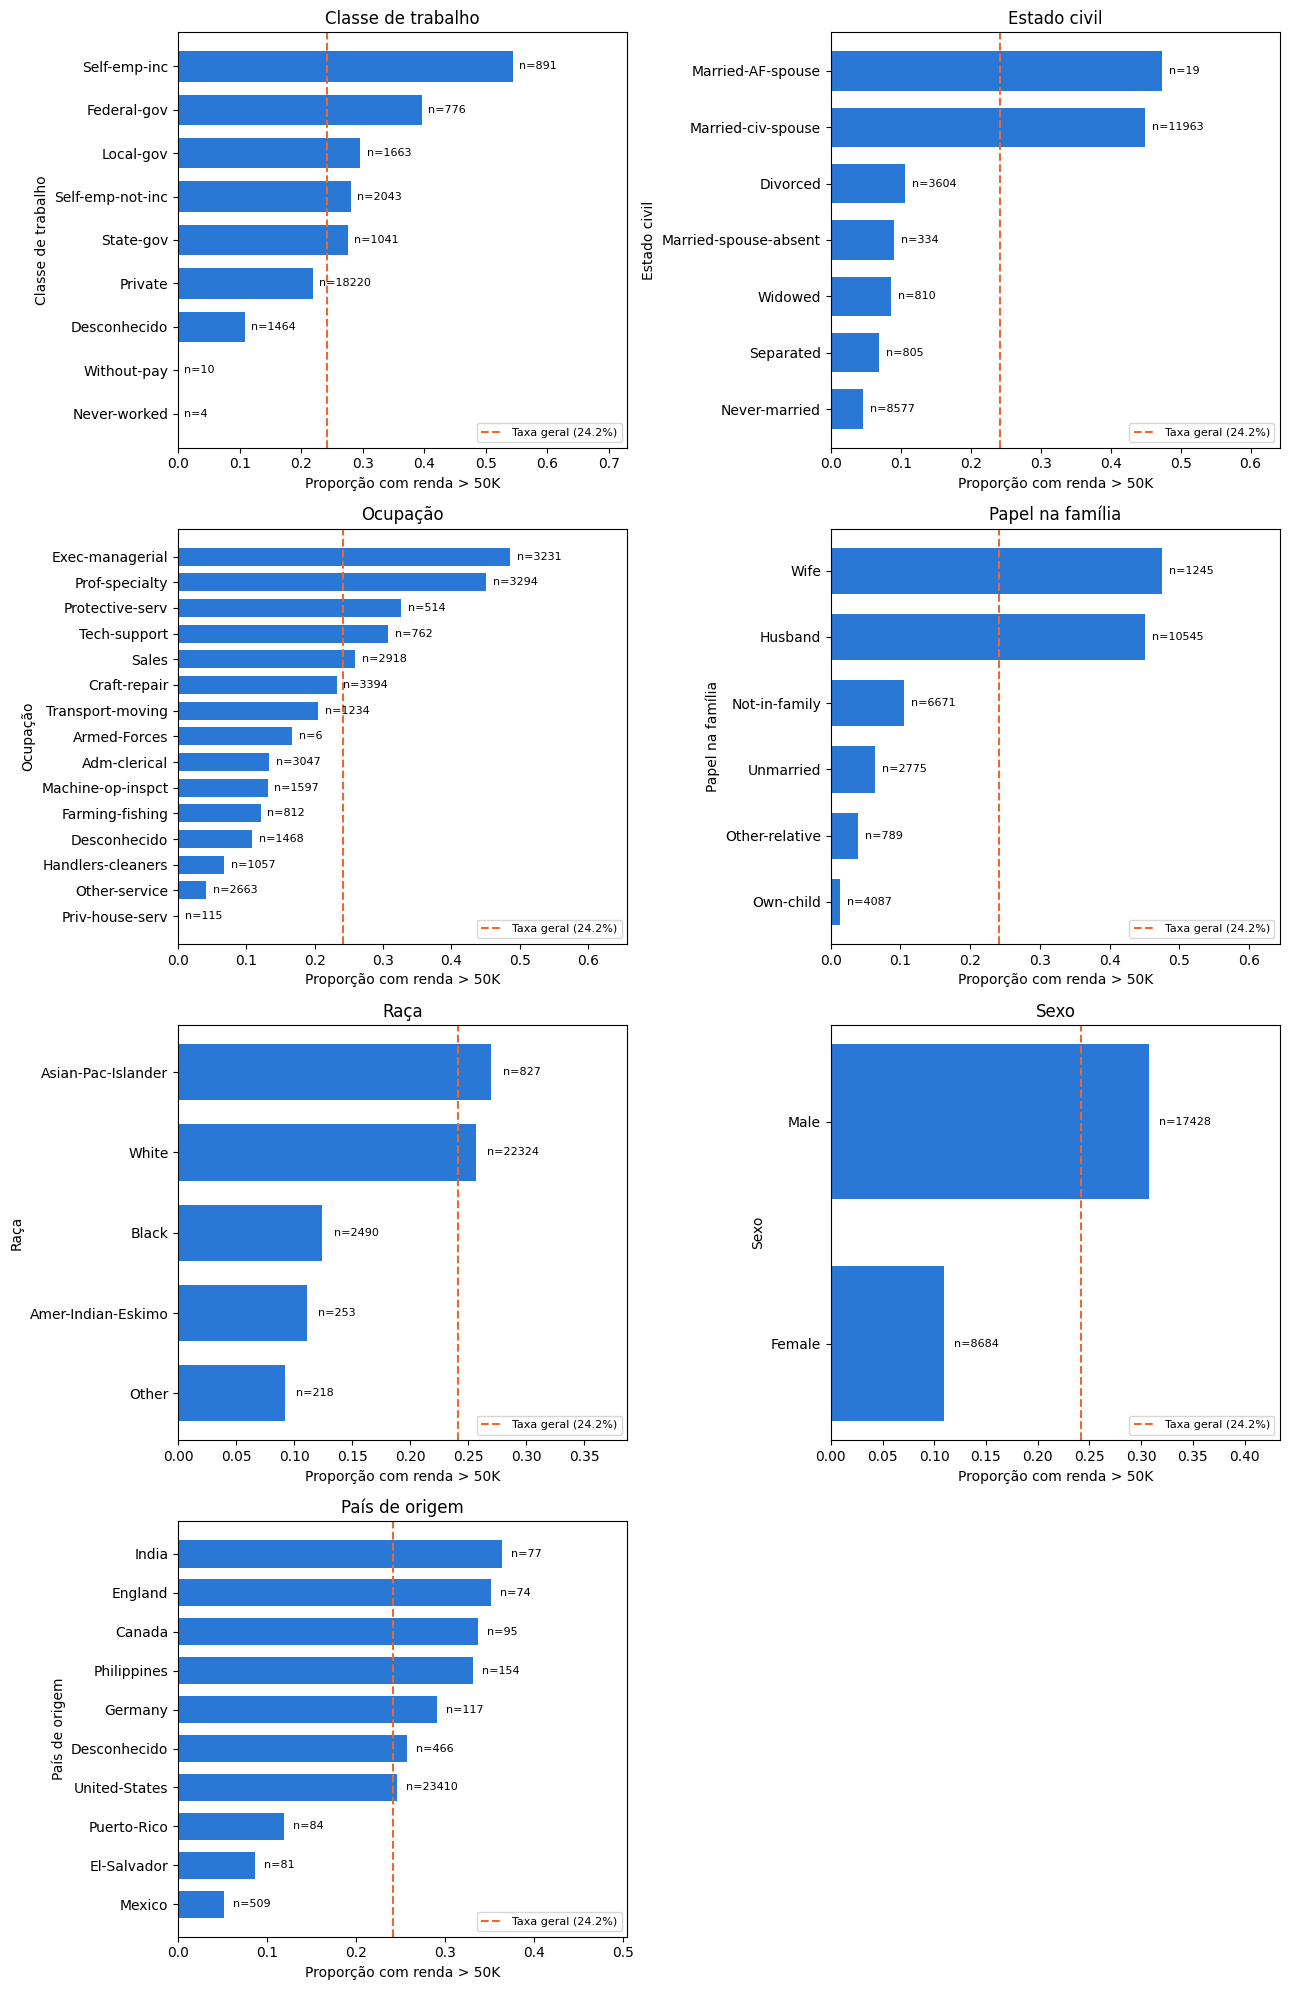

In [336]:
taxa_geral = y_treino.mean()

def plota_taxa(eixo, coluna, top=None):
    tabela = (df_eda.assign(cat=df_eda[coluna].fillna("Desconhecido"))
              .groupby("cat")["alvo"].agg(taxa="mean", n="size"))
    if top:
        tabela = tabela.sort_values("n", ascending=False).head(top)
    tabela = tabela.sort_values("taxa")
    eixo.barh(tabela.index, tabela["taxa"], color="#2a78d6", height=0.7)
    for i, (taxa, n) in enumerate(zip(tabela["taxa"], tabela["n"])):
        eixo.text(taxa + 0.01, i, f"n={n}", va="center", fontsize=8)
    eixo.axvline(taxa_geral, color="#eb6834", linestyle="--", label=f"Taxa geral ({taxa_geral:.1%})")
    eixo.set(xlabel="Proporção com renda > 50K", ylabel=ROTULOS[coluna], title=ROTULOS[coluna])
    eixo.set_xlim(0, min(1.0, tabela["taxa"].max() * 1.25 + 0.05))
    eixo.legend(loc="lower right", fontsize=8)

fig, eixos = plt.subplots(4, 2, figsize=(13, 20))
eixos = eixos.ravel()
for eixo, coluna in zip(eixos, ATRIBUTOS_CATEGORICOS):
    plota_taxa(eixo, coluna, top=10 if coluna == "native-country" else None)
eixos[-1].axis("off")
plt.tight_layout()
plt.show()

**O que vemos.** O estado civil e o papel na família são **muito discriminativos**: pessoas casadas (`Married-civ-spouse`, `Husband`, `Wife`) têm taxa de renda alta bem acima da geral, enquanto "nunca casado" e `Own-child` têm taxas muito baixas. Ocupações executivas e profissionais liberais têm taxas altas; serviços e limpeza, baixas. Há também diferença por sexo e por raça (voltaremos a isso na Seção 13, sobre equidade).


### 5.4 Dados faltantes: a ausência é informativa?

A taxa de renda alta é **bem menor** entre quem tem `workclass`/`occupation` ausentes (em geral, pessoas fora da força de trabalho formal), e os dois atributos faltam quase sempre juntos. Logo, descartar essas linhas jogaria fora padrões reais, e imputar a moda esconderia a informação. Tratar o ausente como categoria `Desconhecido` preserva o sinal.

In [337]:
linhas = []
for coluna in ["workclass", "occupation", "native-country"]:
    ausente = df_eda[coluna].isna()
    linhas.append({
        "atributo": coluna,
        "% ausente": ausente.mean() * 100,
        "taxa > 50K se ausente": df_eda.loc[ausente, "alvo"].mean() * 100,
        "taxa > 50K se presente": df_eda.loc[~ausente, "alvo"].mean() * 100,
    })
display(pd.DataFrame(linhas).set_index("atributo").round(2))

ausente_wc = df_eda["workclass"].isna()
ausente_oc = df_eda["occupation"].isna()
print("\nLinhas em que workclass e occupation faltam juntas:",
      f"{(ausente_wc & ausente_oc).sum()} de {max(ausente_wc.sum(), ausente_oc.sum())}")

,% ausente,taxa > 50K se ausente,taxa > 50K se presente
atributo,,,
workclass,5.61,10.86,24.94
occupation,5.62,10.83,24.95
native-country,1.78,25.75,24.12



Linhas em que workclass e occupation faltam juntas: 1464 de 1468


### 5.5 Relações entre atributos (redundância)

Duas visões: a correlação de **Spearman** entre os atributos numéricos e o target (adequada a distribuições assimétricas) e o **V de Cramér** entre atributos categóricos, uma medida de associação entre 0 (independentes) e 1 (totalmente associados), obtida a partir do qui-quadrado.

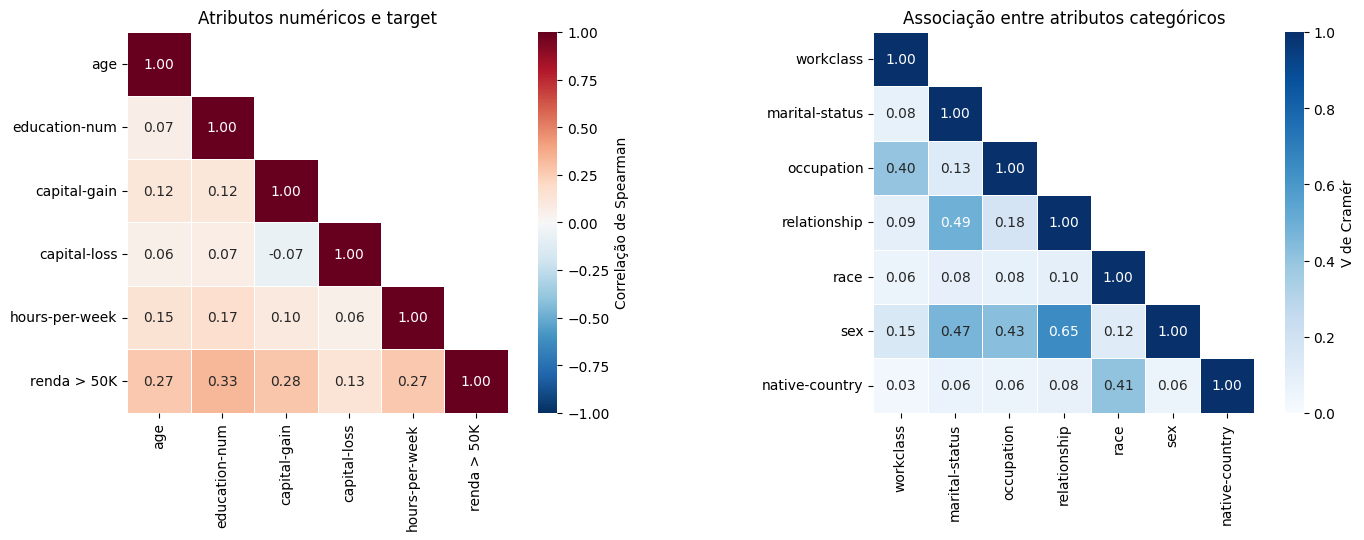

In [338]:
def cramer_v(x, y):
    tabela = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(tabela, correction=False)[0]
    n = tabela.to_numpy().sum()
    phi2 = chi2 / n
    r, k = tabela.shape
    phi2_corr = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2_corr / max(1e-12, min(k_corr - 1, r_corr - 1)))

cat_eda = df_eda[ATRIBUTOS_CATEGORICOS].fillna("Desconhecido")
v_cramer = pd.DataFrame(
    [[cramer_v(cat_eda[a], cat_eda[b]) for b in ATRIBUTOS_CATEGORICOS] for a in ATRIBUTOS_CATEGORICOS],
    index=ATRIBUTOS_CATEGORICOS, columns=ATRIBUTOS_CATEGORICOS,
)
corr_spearman = df_eda[ATRIBUTOS_NUMERICOS + ["alvo"]].corr(method="spearman")
corr_spearman = corr_spearman.rename(index={"alvo": "renda > 50K"}, columns={"alvo": "renda > 50K"})

fig, eixos = plt.subplots(1, 2, figsize=(15, 5.5))
mascara = np.triu(np.ones_like(corr_spearman, dtype=bool), k=1)
sns.heatmap(corr_spearman, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=eixos[0], cbar_kws={"label": "Correlação de Spearman"})
eixos[0].set_title("Atributos numéricos e target")
mascara = np.triu(np.ones_like(v_cramer, dtype=bool), k=1)
sns.heatmap(v_cramer, mask=mascara, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            square=True, linewidths=0.5, ax=eixos[1], cbar_kws={"label": "V de Cramér"})
eixos[1].set_title("Associação entre atributos categóricos")
plt.tight_layout()
plt.show()

**O que vemos.** Os atributos categóricos **não são independentes**: `relationship` e `marital-status` (e também `sex`) são fortemente associados, o que faz sentido (marido/esposa ↔ casado). Essa redundância, somada às dezenas de colunas geradas pelo *one-hot*, é a motivação para testar **seleção de atributos e PCA** (Q2). Entre os numéricos, `education-num`, `age` e `hours-per-week` se correlacionam positivamente com a renda.

### 5.6 Quais atributos carregam informação sobre o target? (informação mútua)

A **informação mútua** mede o quanto conhecer um atributo reduz a incerteza sobre o target, **sem supor relação linear**. Incluímos duas colunas de referência: o `fnlwgt` (que removemos) e uma coluna de **ruído aleatório** (a informação mútua de ruído indica o "piso" de erro da estimativa).

age               0.067148
education-num     0.067463
capital-gain      0.081825
marital-status    0.108509
relationship      0.114577
dtype: float64

ruído aleatório (referência)    0.000000
fnlwgt (removido)               0.026962
dtype: float64


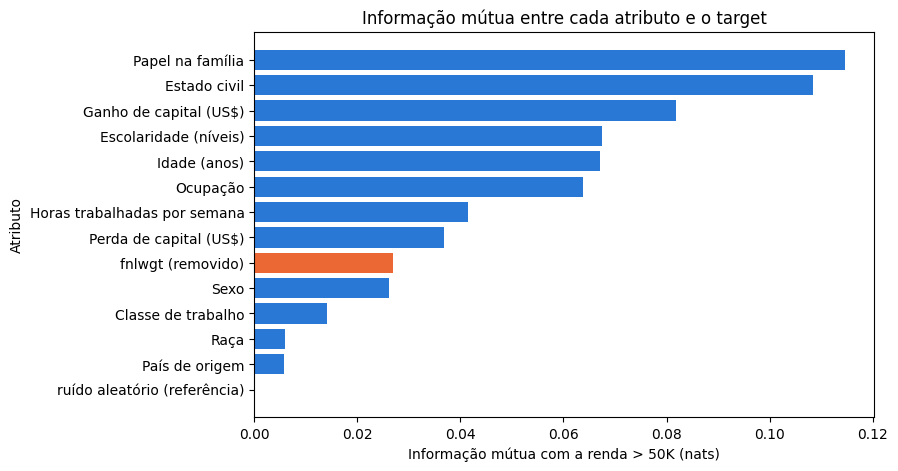

In [339]:
rng = np.random.default_rng(SEMENTE)
bruto_treino = df_bruto.iloc[indices_treino].reset_index(drop=True)

mi_df = X_treino.copy()
mi_df["fnlwgt (removido)"] = bruto_treino["fnlwgt"].values
mi_df["ruído aleatório (referência)"] = rng.normal(size=len(mi_df))

mi_df[ATRIBUTOS_CATEGORICOS] = mi_df[ATRIBUTOS_CATEGORICOS].fillna("Desconhecido")
colunas_mi = list(mi_df.columns)
eh_discreto = [c in ATRIBUTOS_CATEGORICOS for c in colunas_mi]
mi_X = mi_df.copy()
mi_X[ATRIBUTOS_CATEGORICOS] = OrdinalEncoder().fit_transform(mi_df[ATRIBUTOS_CATEGORICOS])

mi = mutual_info_classif(mi_X, y_treino, discrete_features=eh_discreto, random_state=SEMENTE)
mi = pd.Series(mi, index=colunas_mi).sort_values()

fig, eixo = plt.subplots(figsize=(8, 5))
cores = ["#eb6834" if c.startswith(("fnlwgt", "ruído")) else "#2a78d6" for c in mi.index]
eixo.barh([ROTULOS.get(c, c) for c in mi.index], mi.values, color=cores)
eixo.set(xlabel="Informação mútua com a renda > 50K (nats)", ylabel="Atributo",
         title="Informação mútua entre cada atributo e o target")
print(mi.tail(5))
print()
print(mi[mi.index.str.contains("ruído|fnlwgt", case=False)])
plt.show()


Os atributos mais informativos são `relationship`, `marital-status`, `capital-gain`, `age`, `education-num` e `occupation`. O `fnlwgt` (laranja) tem informação mútua **acima** do ruído aleatório e comparável à de `sex`, então **não** podemos dizer que ele seja "inútil" só por este gráfico (o estimador também tende a inflar a informação de variáveis contínuas com muitos valores distintos). A remoção continua sendo uma decisão **conceitual**, explicada na Seção 3.3: o `fnlwgt` descreve o desenho amostral do censo, não a pessoa, e um modelo que o use estaria aprendendo sobre a amostragem e não sobre a renda. Atributos como `race` e `native-country` carregam pouca informação marginal.

### 5.7 Síntese da EDA e decisões de modelagem

| Achado | Decisão |
|---|---|
| Classes desbalanceadas (~24% positivas) | Não usar acurácia como métrica principal. Otimizar **PR-AUC**; reportar também ROC-AUC, F1, acurácia balanceada; usar validação cruzada **estratificada**. |
| Exemplos redundantes | Divisão e validação cruzada **agrupadas** (`StratifiedGroupKFold`). |
| Escalas muito diferentes; `capital-*` muito assimétricos | Normalizar (padrão ou min-max, escolhido pelo Optuna) nos modelos sensíveis à escala; aplicar `log(1+x)` aos `capital-*`. Árvores e *boosting* não precisam de normalização. |
| Ausentes informativos | Categoria `Desconhecido` dentro do pipeline. |
| Categorias raras (ex.: países com poucas pessoas) | Deixar o Optuna escolher a **frequência mínima** abaixo da qual categorias são agrupadas no *one-hot*. |
| Redundância entre atributos e muitas colunas após *one-hot* | Deixar o Optuna controlar **seleção de atributos / PCA** em regressão logística e *k*-NN. |
| `fnlwgt` é peso amostral (não descreve a pessoa); `education` é redundante com `education-num` | Removidos. |

## 6. Estratégia de avaliação

### 6.1 Métricas

Como o target é desbalanceado, usamos métricas que não se enganam com a classe majoritária. Seja a classe positiva "renda > 50K" e VP, FP, VN, FN os valores da matriz de confusão (como na aula de métricas):

| Métrica | Definição | Intuição |
|---|---|---|
| **PR-AUC** (*average precision*) | área sob a curva precisão × sensibilidade | **Métrica de otimização**. Resume o equilíbrio entre precisão e sensibilidade em *todos* os limiares, e é a recomendada para dados desbalanceados [4]. Um modelo que chuta ao acaso tem PR-AUC ≈ proporção de positivos (~0,24). |
| **ROC-AUC** | área sob a curva sensibilidade × (1 − especificidade) | Probabilidade de um positivo qualquer receber probabilidade maior que um negativo qualquer. Chute: 0,5. Pode parecer otimista com desbalanceamento. |
| **F1** | $\frac{2VP}{2VP + FP + FN}$ | Média harmônica de precisão e sensibilidade, **depende do limiar** (padrão 0,5). |
| **Acurácia balanceada** | média da sensibilidade das duas classes | Acurácia que "pesa" as classes igualmente. |
| **Precisão / Sensibilidade** | $\frac{VP}{VP+FP}$ / $\frac{VP}{VP+FN}$ | Dos que prevemos > 50K, quantos de fato são? / Dos que são > 50K, quantos achamos? |
| **MCC** | correlação entre previsão e verdade | Resumo único robusto a desbalanceamento. |

**Por que otimizar uma métrica que não depende de limiar?** Porque o limiar de decisão (0,5 por padrão) é uma escolha *separada* do modelo; otimizá-lo é tema da Seção 11. Assim, a busca de hiperparâmetros se concentra na **qualidade do ranqueamento** das probabilidades.

### 6.2 Validação cruzada estratificada e agrupada

Todos os modelos são avaliados com `StratifiedGroupKFold` (5 folds) **dentro do conjunto de treino**:

-   *estratificada*: cada fold mantém a proporção de ~24% de positivos;
-   *agrupada*: um mesmo grupo de exemplos quase redundantes nunca fica em dois folds diferentes (mesmo cuidado da Seção 4, agora para o treino × validação).

Durante a otimização, **todas as tentativas usam exatamente os mesmos folds** (semente fixa), para que a comparação entre configurações seja justa.

In [340]:
cv_otimizacao = StratifiedGroupKFold(n_splits=NUM_FOLDS, shuffle=True, random_state=SEMENTE)

folds = []
for i, (itr, ival) in enumerate(cv_otimizacao.split(X_treino, y_treino, groups=grupos_treino), start=1):
    folds.append({"fold": i, "n treino": len(itr), "n validação": len(ival),
                  "% positivos na validação": round(y_treino.iloc[ival].mean() * 100, 2)})
pd.DataFrame(folds).set_index("fold")

,n treino,n validação,% positivos na validação
fold,,,
1,20763,5349,24.70
2,20831,5281,24.01
3,21079,5033,23.82
4,20971,5141,23.83
5,20804,5308,24.38


## 7. Pré-processamento e modelo *baseline*

### 7.1 Pré-processamento dentro do `Pipeline`

Todas as transformações com etapa de ajuste (normalização, *one-hot*, imputação, seleção, PCA) ficam **dentro de um `Pipeline`**. Assim, durante a validação cruzada, cada transformação é ajustada apenas nos dados de treino de cada fold e aplicada no fold de validação, o que **evita o vazamento por pré-processamento** discutido na aula (normalizar antes de dividir é um erro clássico).

A função `cria_preprocessador` monta um `ColumnTransformer` com duas variantes:

-   **com escala** (para regressão logística e *k*-NN): numéricos "simétricos" (`age`, `education-num`, `hours-per-week`) são normalizados; `capital-gain` e `capital-loss` recebem `log(1+x)` e depois normalização; categóricos são imputados (`Desconhecido`) e codificados em *one-hot*. O tipo de normalização (`padrao` = z-score, `minmax` = [0, 1]) e a frequência mínima de categorias (`freq_min`) são **hiperparâmetros** que o Optuna escolhe.
-   **sem escala** (árvore e floresta): numéricos passam direto, pois árvores são invariantes a transformações monotônicas dos atributos.

O *gradient boosting* usa uma terceira variante (Seção 8.6), com codificação ordinal e suporte nativo a categorias.

In [341]:
ATRIBUTOS_NUM_SIMETRICOS = ["age", "education-num", "hours-per-week"]
ATRIBUTOS_NUM_ASSIMETRICOS = ["capital-gain", "capital-loss"]


def cria_preprocessador(escalar=True, escalador="padrao", freq_min=1):
    categoricos = Pipeline([
        ("imputador", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
        ("one_hot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=freq_min,
                                  drop="if_binary", sparse_output=False)),
    ])

    if not escalar:
        return ColumnTransformer([
            ("numericos", "passthrough", ATRIBUTOS_NUMERICOS),
            ("categoricos", categoricos, ATRIBUTOS_CATEGORICOS),
        ])

    Escalador = {"padrao": StandardScaler, "minmax": MinMaxScaler}[escalador]
    return ColumnTransformer([
        ("num_simetricos", Escalador(), ATRIBUTOS_NUM_SIMETRICOS),
        ("num_assimetricos", Pipeline([
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            ("escala", Escalador()),
        ]), ATRIBUTOS_NUM_ASSIMETRICOS),
        ("categoricos", categoricos, ATRIBUTOS_CATEGORICOS),
    ])


demo = cria_preprocessador().fit(X_treino)
matriz_demo = demo.transform(X_treino)
print(f"Matriz transformada: {matriz_demo.shape[0]} exemplos × {matriz_demo.shape[1]} colunas "
      f"(a partir de {len(ATRIBUTOS)} atributos originais)")
print("Primeiras colunas:", list(demo.get_feature_names_out()[:8]))

Matriz transformada: 26112 exemplos × 90 colunas (a partir de 12 atributos originais)
Primeiras colunas: ['num_simetricos__age', 'num_simetricos__education-num', 'num_simetricos__hours-per-week', 'num_assimetricos__capital-gain', 'num_assimetricos__capital-loss', 'categoricos__workclass_Desconhecido', 'categoricos__workclass_Federal-gov', 'categoricos__workclass_Local-gov']


Os 12 atributos originais viram dezenas de colunas após o *one-hot* (principalmente por `native-country`, `occupation` e `workclass`). Isso é o que justifica estudar seleção de atributos e redução de dimensionalidade.

### 7.2 Baseline

Todo projeto de aprendizado de máquina deve começar por um **modelo baseline**: o desempenho mínimo a ser superado. Usamos o `DummyClassifier(strategy="prior")`, que ignora os atributos, **sempre prevê a classe majoritária** e atribui a todos a probabilidade igual à proporção de positivos do treino.

Avaliamos com a mesma validação cruzada que será usada nos demais modelos.

In [342]:
METRICAS_CV = {
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
    "f1": make_scorer(f1_score, zero_division=0),
    "acc_bal": "balanced_accuracy",
    "acuracia": "accuracy",
}

def avalia_cv(modelo, semente=SEMENTE, n_jobs=1):
    
    cv = StratifiedGroupKFold(n_splits=NUM_FOLDS, shuffle=True, random_state=semente)
    r = cross_validate(modelo, X_treino, y_treino, groups=grupos_treino, cv=cv,
                       scoring=METRICAS_CV, n_jobs=n_jobs)
    df_r = pd.DataFrame({m: r[f"test_{m}"] for m in METRICAS_CV})
    df_r.insert(0, "fold", np.arange(1, len(df_r) + 1))
    df_r.insert(0, "semente", semente)
    return df_r

baseline = DummyClassifier(strategy="prior")
res_baseline = avalia_cv(baseline)
display(res_baseline.drop(columns="semente").set_index("fold").round(3))
print("\nMédias dos 5 folds:")
display(res_baseline[list(METRICAS_CV)].mean().round(3).to_frame("baseline").T)

,pr_auc,roc_auc,f1,acc_bal,acuracia
fold,,,,,
1,0.247,0.5,0.0,0.5,0.753
2,0.240,0.5,0.0,0.5,0.760
3,0.238,0.5,0.0,0.5,0.762
4,0.238,0.5,0.0,0.5,0.762
5,0.244,0.5,0.0,0.5,0.756



Médias dos 5 folds:


,pr_auc,roc_auc,f1,acc_bal,acuracia
baseline,0.241,0.5,0.0,0.5,0.759


**Leitura.** O baseline tem **acurácia alta (~0,76)** mas é inútil: F1 = 0 (nunca prevê a classe positiva), acurácia balanceada = 0,5, ROC-AUC = 0,5 e PR-AUC igual à proporção de positivos (~0,24). Isso ilustra por que não olhamos só a acurácia. **Qualquer modelo útil precisa superar PR-AUC ≈ 0,24 e ROC-AUC ≈ 0,5.**

## 8. Otimização de hiperparâmetros com Optuna

### 8.1 Como o Optuna funciona (e como o usamos)

O **Optuna** [5] é um *framework* de otimização de hiperparâmetros. Em vez de testar todas as combinações (busca em grade) ou sortear ao acaso (busca aleatória), ele usa os resultados das tentativas anteriores para **decidir onde vale a pena testar a seguir**. Vocabulário:

-   **Espaço de busca**: o conjunto de valores permitidos para cada hiperparâmetro, definido com `trial.suggest_int`, `suggest_float` e `suggest_categorical`.
-   **Tentativa** (*trial*): uma combinação de hiperparâmetros sorteada pelo Optuna e avaliada pela **função objetivo**.
-   **Estudo** (*study*): o conjunto de tentativas de um mesmo problema; guardamos cada estudo em um arquivo SQLite (`estudos/*.db`).
-   **Amostrador**: o algoritmo que escolhe a próxima tentativa. Usamos o padrão, o **TPE** (*Tree-structured Parzen Estimator*) [6], que modela, de forma bayesiana, a distribuição dos hiperparâmetros das tentativas "boas" e "ruins" e sorteia valores com maior chance de pertencerem ao grupo das boas. Ativamos `multivariate=True` (considera a dependência entre hiperparâmetros) e `group=True` (necessário porque nosso espaço é **condicional**: o parâmetro `variancia_pca` só existe se o Optuna escolher o PCA). A semente do amostrador é fixa, para reprodutibilidade.

**Função objetivo.** Para cada tentativa construímos o pipeline completo (pré-processamento + redução + algoritmo) e calculamos a **PR-AUC média na validação cruzada estratificada e agrupada de 5 folds, no conjunto de treino**. O conjunto de teste não participa. Queremos **maximizar** esse valor.

**Escala logarítmica.** Hiperparâmetros que variam por ordens de grandeza (como `C`, taxa de aprendizado, `ccp_alpha`) são sorteados em escala logarítmica (`log=True`), para evitar o *viés de amostragem* discutido no apêndice do notebook de Optuna (sem isso, 90% dos sorteios cairiam na ordem de grandeza mais alta).

**Número de tentativas.** Cada um dos 5 pipelines recebe **100 tentativas** (o mínimo exigido). Não usamos poda (*pruning*) para que as 100 tentativas sejam todas avaliadas por completo.

**Retomada.** Como em aula (`load_if_exists=True`), se o arquivo do estudo já existir, o notebook conta quantas tentativas já foram concluídas e roda **apenas as que faltam**. Como o TPE pode, de vez em quando, sugerir de novo uma combinação já avaliada, o critério é ter **100 combinações distintas** concluídas: se houver repetições, o notebook roda tentativas extras até completar esse número.

In [343]:
os.makedirs(PASTA_ESTUDOS, exist_ok=True)


def cria_ou_carrega_estudo(nome):
    return optuna.create_study(
        direction="maximize",
        study_name=nome,
        storage=f"sqlite:///{PASTA_ESTUDOS}/{nome}.db",
        load_if_exists=True,
        sampler=optuna.samplers.TPESampler(seed=SEMENTE, multivariate=True, group=True),
    )


def funcao_objetivo(trial, cria_modelo, n_jobs_cv):
    from sklearn.model_selection import cross_val_score

    modelo = cria_modelo(trial)
    scores = cross_val_score(
        modelo, X_treino, y_treino, groups=grupos_treino, cv=cv_otimizacao,
        scoring="average_precision", n_jobs=n_jobs_cv, error_score="raise",
    )
    trial.set_user_attr("scores_folds", [float(s) for s in scores])
    return float(scores.mean())


def conta_concluidas_e_distintas(estudo):
    df_t = estudo.trials_dataframe()
    if df_t.empty or "state" not in df_t.columns:
        return 0, 0                      # estudo novo, sem tentativas
    df_t = df_t[df_t["state"] == "COMPLETE"]
    colunas_params = [c for c in df_t.columns if c.startswith("params_")]
    if df_t.empty or not colunas_params:
        return len(df_t), 0
    distintas = df_t[colunas_params].astype(str).drop_duplicates().shape[0]
    return len(df_t), distintas


def otimiza(nome, cria_modelo, n_jobs_cv=1):
    estudo = cria_ou_carrega_estudo(nome)
    concluidas, distintas = conta_concluidas_e_distintas(estudo)
    inicial = concluidas
    inicio = time.time()
    while min(concluidas, distintas) < NUM_TENTATIVAS:
        faltam = NUM_TENTATIVAS - min(concluidas, distintas)
        estudo.optimize(partial(funcao_objetivo, cria_modelo=cria_modelo, n_jobs_cv=n_jobs_cv), n_trials=faltam)
        concluidas, distintas = conta_concluidas_e_distintas(estudo)
    print(f"[{nome}] tentativas já existentes: {inicial} | rodadas agora: {concluidas - inicial} | "
          f"concluídas: {concluidas} (distintas: {distintas}) | "
          f"tempo desta execução: {(time.time() - inicio) / 60:.1f} min | melhor PR-AUC (CV): {estudo.best_value:.4f}")
    return estudo


def resume_estudo(estudo, titulo, cor):
    melhor = estudo.best_trial
    desvio = np.std(melhor.user_attrs["scores_folds"])
    print(f"Melhor tentativa: nº {melhor.number} | PR-AUC média (CV) = {melhor.value:.4f} ± {desvio:.4f} (desvio entre folds)")
    display(pd.Series(melhor.params, name="melhor valor").to_frame())

    df_t = estudo.trials_dataframe()
    df_t = df_t[df_t["state"] == "COMPLETE"]
    fig, eixos = plt.subplots(1, 2, figsize=(13, 4))

    eixos[0].scatter(df_t["number"], df_t["value"], s=18, color=cor, alpha=0.55, label="Tentativa")
    eixos[0].plot(df_t["number"], df_t["value"].cummax(), color="black", lw=2, label="Melhor até o momento")
    eixos[0].set(xlabel="Número da tentativa", ylabel="PR-AUC média na validação cruzada",
                 title=f"Histórico de otimização: {titulo}")
    eixos[0].legend(loc="lower right")

    try:
        imp = pd.Series(optuna.importance.get_param_importances(estudo)).sort_values()
        eixos[1].barh(imp.index, imp.values, color=cor)
        eixos[1].set(xlabel="Importância do hiperparâmetro (fração da variância da PR-AUC)",
                     ylabel="Hiperparâmetro", title="Importância dos hiperparâmetros")
    except Exception as erro:
        eixos[1].text(0.5, 0.5, f"Importâncias indisponíveis\n({type(erro).__name__})", ha="center")
        eixos[1].set_axis_off()
    plt.tight_layout()
    plt.show()


def monta(preprocessador, reducao, estimador):
    return Pipeline([("prep", preprocessador), ("reducao", reducao), ("modelo", estimador)])


def cria_reducao(trial):
    tipo = trial.suggest_categorical("reducao", ["nenhuma", "selecao_percentil", "pca"])
    if tipo == "selecao_percentil":
        return SelectPercentile(f_classif, percentile=trial.suggest_int("percentil", 10, 100, step=5))
    if tipo == "pca":
        return PCA(n_components=trial.suggest_float("variancia_pca", 0.50, 0.99), svd_solver="full")
    return "passthrough"

### 8.2 Pipeline 1: regressão logística com seleção/redução de atributos controlada pelo Optuna

**O algoritmo.** A regressão logística modela a probabilidade da classe positiva como $P(y=1|x) = 1/(1+e^{-(\beta_0+\beta_1 x_1+\cdots)})$. É um modelo **linear** e interpretável, sensível à escala dos atributos (por isso a normalização) e que costuma ser um bom ponto de partida para dados tabulares.

**O que o Optuna controla neste pipeline.**

| Hiperparâmetro | Espaço de busca | Por que este intervalo? |
|---|---|---|
| `escalador` | `padrao` ou `minmax` | Os dois normalizadores vistos em aula; a regularização depende da escala. |
| `freq_min` | inteiro de 1 a 500 (log) | Agrupa categorias com menos de `freq_min` exemplos (ex.: países raros). 1 = sem agrupamento; 500 ≈ 2% do treino. Escala log pois o efeito é relativo. |
| `reducao` | `nenhuma`, `selecao_percentil`, `pca` | Responde à Q2: o Optuna decide **se** reduz a dimensionalidade e **como**. |
| `percentil` (se seleção) | 10 a 100, passo 5 | Mantém de 10% a 100% das colunas, ranqueadas pelo teste F (ANOVA) entre cada coluna e o target. Abaixo de 10% sobrariam poucas colunas. |
| `variancia_pca` (se PCA) | 0,50 a 0,99 | Fração mínima da variância total a reter: define quantas componentes principais ficam (ver notebook de PCA). Abaixo de 50% se perde informação demais. |
| `C` | 1e-4 a 1e2 (log) | Inverso da força de regularização. Seis ordens de grandeza: de regularização muito forte (modelo quase constante) a muito fraca (risco de sobreajuste). |
| `penalidade` | `l2` ou `l1` | L2 encolhe coeficientes; L1 zera coeficientes (seleção embutida de atributos). |
| `class_weight` | `None` ou `balanced` | Pondera as classes inversamente à frequência; pode mudar o ranqueamento em dados desbalanceados. |

**Fixos:** solver `liblinear` (rápido e suporta L1 e L2 neste tamanho de dados), `max_iter=1000`.

In [344]:

def cria_modelo_lr(trial):
    """Pipeline 1: pré-processamento + (redução opcional) + regressão logística."""
    prep = cria_preprocessador(
        escalar=True,
        escalador=trial.suggest_categorical("escalador", ["padrao", "minmax"]),
        freq_min=trial.suggest_int("freq_min", 1, 500, log=True),
    )
    reducao = cria_reducao(trial)
    penalidade = trial.suggest_categorical("penalidade", ["l2", "l1"])
    modelo = LogisticRegression(
        C=trial.suggest_float("C", 1e-4, 1e2, log=True),
        l1_ratio=0.0 if penalidade == "l2" else 1.0,   # 0 = L2, 1 = L1
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
        solver="liblinear", max_iter=1000, random_state=SEMENTE,
    )
    return monta(prep, reducao, modelo)


estudo_lr = otimiza("regressao_logistica", cria_modelo_lr, n_jobs_cv=2)

[regressao_logistica] tentativas já existentes: 517 | rodadas agora: 0 | concluídas: 517 (distintas: 517) | tempo desta execução: 0.0 min | melhor PR-AUC (CV): 0.7401


Melhor tentativa: nº 242 | PR-AUC média (CV) = 0.7401 ± 0.0098 (desvio entre folds)


,melhor valor
escalador,minmax
freq_min,37
reducao,nenhuma
penalidade,l2
C,0.616636
class_weight,None


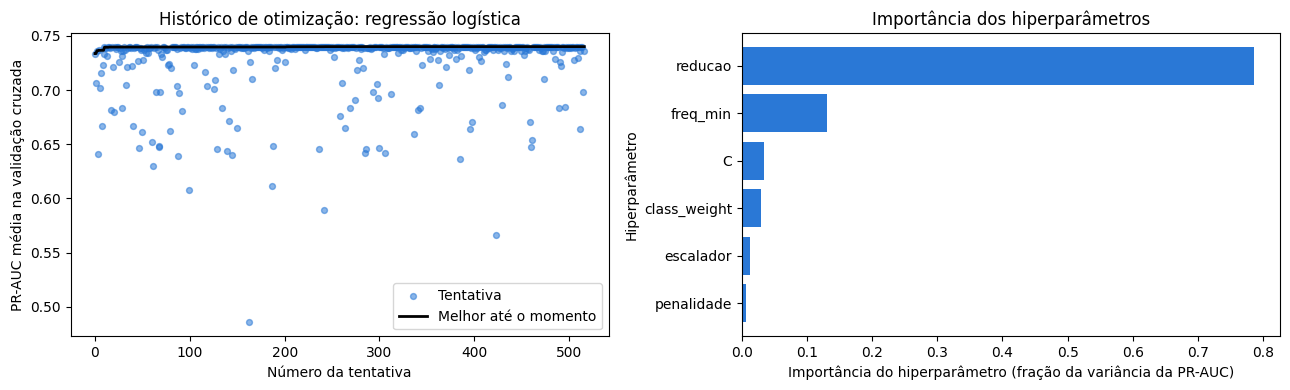

In [345]:
CORES_MODELOS = {"Baseline": "#7a7a75", "Regressão logística": "#2a78d6", "k-NN": "#eb6834",
                 "Árvore de decisão": "#1baf7a", "Floresta aleatória": "#6250d6",
                 "Gradient boosting": "#e34948"}

resume_estudo(estudo_lr, "regressão logística", CORES_MODELOS["Regressão logística"])

In [346]:
def cria_modelo_knn(trial):
    """Pipeline 2: pré-processamento + (redução opcional) + k-NN."""
    prep = cria_preprocessador(
        escalar=True,
        escalador=trial.suggest_categorical("escalador", ["padrao", "minmax"]),
        freq_min=trial.suggest_int("freq_min", 1, 500, log=True),
    )
    reducao = cria_reducao(trial)
    modelo = KNeighborsClassifier(
        n_neighbors=trial.suggest_int("num_vizinhos", 1, 200, log=True),
        weights=trial.suggest_categorical("pesos", ["uniform", "distance"]),
        p=trial.suggest_categorical("p", [1, 2]),
        n_jobs=1,
    )
    return monta(prep, reducao, modelo)


estudo_knn = otimiza("knn", cria_modelo_knn, n_jobs_cv=2)

[knn] tentativas já existentes: 0 | rodadas agora: 100 | concluídas: 100 (distintas: 100) | tempo desta execução: 10.8 min | melhor PR-AUC (CV): 0.7542


Melhor tentativa: nº 84 | PR-AUC média (CV) = 0.7542 ± 0.0126 (desvio entre folds)


,melhor valor
escalador,padrao
freq_min,11
reducao,nenhuma
num_vizinhos,63
pesos,distance
p,1


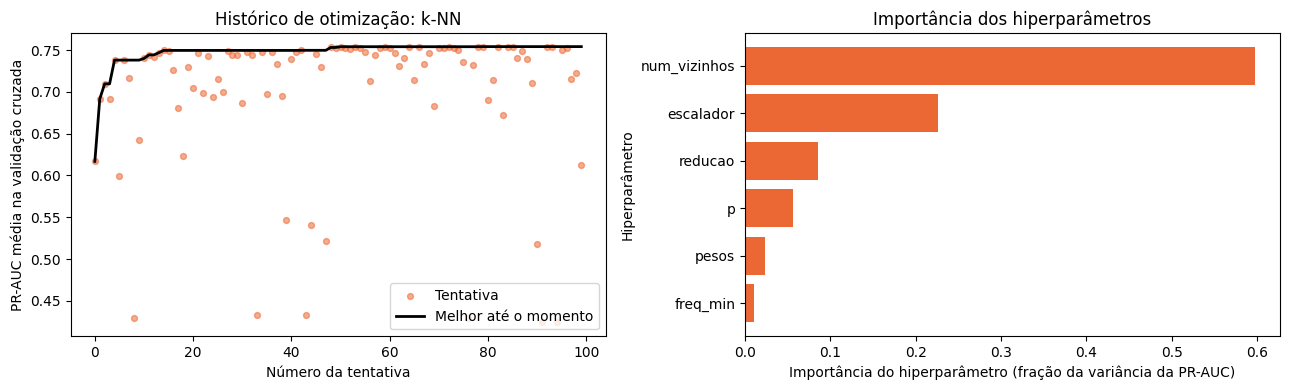

In [347]:
resume_estudo(estudo_knn, "k-NN", CORES_MODELOS["k-NN"])

### 8.4 Pipeline 3: árvore de decisão

**O algoritmo.** Uma árvore de decisão particiona o espaço de atributos com perguntas do tipo "idade ≤ 33?" e, em cada folha, prevê a classe majoritária (ou a proporção de positivos). É interpretável e não precisa de normalização, mas, sem restrições, **cresce até decorar o treino** (sobreajuste). Os hiperparâmetros abaixo controlam a **complexidade** da árvore.

| Hiperparâmetro | Espaço de busca | Por que este intervalo? |
|---|---|---|
| `freq_min` | 1 a 500 (log) | Agrupamento de categorias raras no *one-hot*. |
| `criterio` | `gini`, `entropy`, `log_loss` | As três medidas de impureza disponíveis. |
| `max_depth` | 2 a 30 | Profundidade máxima: 2 é um "toco" quase inútil; 30 é praticamente sem limite para estes dados. |
| `min_samples_split` | 2 a 200 (log) | Mínimo de exemplos para dividir um nó; valores altos evitam divisões em amostras minúsculas. |
| `min_samples_leaf` | 1 a 100 (log) | Mínimo de exemplos por folha; principal arma contra folhas "decoradas". Também importante para que as probabilidades sejam informativas (folhas com 1 exemplo dão 0 ou 1). |
| `ccp_alpha` | 1e-7 a 1e-2 (log) | Poda por custo-complexidade: penaliza o número de folhas. Escala log pois atua em várias ordens de grandeza. |
| `max_features` | `None`, `sqrt`, `log2` | Quantos atributos considerar em cada divisão (injeta aleatoriedade e reduz variância). |
| `class_weight` | `None` ou `balanced` | Ponderação das classes. |

In [349]:
def cria_modelo_arvore(trial):
    """Pipeline 3: pré-processamento (sem escala) + árvore de decisão."""
    prep = cria_preprocessador(escalar=False, freq_min=trial.suggest_int("freq_min", 1, 500, log=True))
    modelo = DecisionTreeClassifier(
        criterion=trial.suggest_categorical("criterio", ["gini", "entropy", "log_loss"]),
        max_depth=trial.suggest_int("max_depth", 2, 30),
        min_samples_split=trial.suggest_int("min_samples_split", 2, 200, log=True),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 100, log=True),
        ccp_alpha=trial.suggest_float("ccp_alpha", 1e-7, 1e-2, log=True),
        max_features=trial.suggest_categorical("max_features", [None, "sqrt", "log2"]),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
        random_state=SEMENTE,
    )
    return Pipeline([("prep", prep), ("modelo", modelo)])


estudo_arvore = otimiza("arvore_decisao", cria_modelo_arvore, n_jobs_cv=2)

[arvore_decisao] tentativas já existentes: 0 | rodadas agora: 100 | concluídas: 100 (distintas: 100) | tempo desta execução: 4.9 min | melhor PR-AUC (CV): 0.7826


Melhor tentativa: nº 15 | PR-AUC média (CV) = 0.7826 ± 0.0114 (desvio entre folds)


,melhor valor
freq_min,34
criterio,log_loss
max_depth,25
min_samples_split,2
min_samples_leaf,34
ccp_alpha,0.0
max_features,None
class_weight,balanced


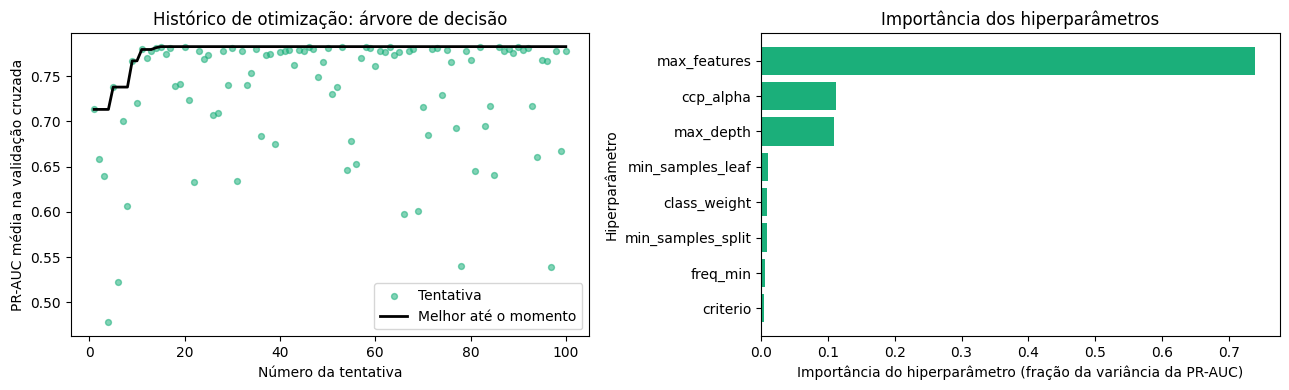

In [350]:
resume_estudo(estudo_arvore, "árvore de decisão", CORES_MODELOS["Árvore de decisão"])

### 8.5 Pipeline 4: floresta aleatória

**O algoritmo.** Uma floresta aleatória [7] treina muitas árvores em **amostras *bootstrap*** dos dados e, em cada divisão, considera apenas um **subconjunto aleatório de atributos**; a previsão é a média das árvores. Isso reduz a variância de uma árvore isolada.

| Hiperparâmetro | Espaço de busca | Por que este intervalo? |
|---|---|---|
| `freq_min` | 1 a 500 (log) | Agrupamento de categorias raras. |
| `n_estimators` | 50 a 300 (log) | Número de árvores: mais árvores estabilizam a média, com retorno decrescente e custo linear. Acima de ~300 o ganho é desprezível para este tamanho de dados. |
| `max_depth` | 4 a 40 | Controla a complexidade de cada árvore. |
| `min_samples_split` | 2 a 100 (log) | Mínimo para dividir um nó. |
| `min_samples_leaf` | 1 a 50 (log) | Mínimo por folha: regulariza e melhora a qualidade das probabilidades. |
| `frac_max_atributos` | 0,05 a 1,0 | Fração das colunas sorteadas a cada divisão (o `max_features`, um dos hiperparâmetros mais importantes da floresta). Com ~90 colunas, o padrão ($\sqrt{p}$) é ~0,1; 1,0 equivale a *bagging* puro. |
| `criterio` | `gini` ou `entropy` | Medida de impureza. |
| `class_weight` | `None`, `balanced`, `balanced_subsample` | Ponderação das classes (global ou recalculada em cada amostra *bootstrap*). |
| `max_samples` | 0,3 a 1,0 | Fração dos dados em cada árvore: valores menores diversificam as árvores e aceleram o treino. |

In [351]:
def cria_modelo_floresta(trial):
    """Pipeline 4: pré-processamento (sem escala) + floresta aleatória."""
    prep = cria_preprocessador(escalar=False, freq_min=trial.suggest_int("freq_min", 1, 500, log=True))
    modelo = RandomForestClassifier(
        n_estimators=trial.suggest_int("n_estimators", 50, 300, log=True),
        max_depth=trial.suggest_int("max_depth", 4, 40),
        min_samples_split=trial.suggest_int("min_samples_split", 2, 100, log=True),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 50, log=True),
        max_features=trial.suggest_float("frac_max_atributos", 0.05, 1.0),
        criterion=trial.suggest_categorical("criterio", ["gini", "entropy"]),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced", "balanced_subsample"]),
        max_samples=trial.suggest_float("max_samples", 0.3, 1.0),
        bootstrap=True, n_jobs=-1, random_state=SEMENTE,
    )
    return Pipeline([("prep", prep), ("modelo", modelo)])


estudo_floresta = otimiza("floresta_aleatoria", cria_modelo_floresta, n_jobs_cv=1)

[floresta_aleatoria] tentativas já existentes: 0 | rodadas agora: 100 | concluídas: 100 (distintas: 100) | tempo desta execução: 11.4 min | melhor PR-AUC (CV): 0.8102


In [ ]:
resume_estudo(estudo_floresta, "floresta aleatória", CORES_MODELOS["Floresta aleatória"])

### 8.6 Pipeline 5: *gradient boosting* de histogramas (`HistGradientBoostingClassifier`)

**O algoritmo.** No *gradient boosting* [8], as árvores são treinadas **em sequência**, cada uma corrigindo os erros das anteriores (por isso são árvores rasas, "fracas"). A versão por histogramas do `scikit-learn` discretiza os atributos em *bins*, o que a torna muito rápida, e tem **suporte nativo a atributos categóricos**: por isso este pipeline usa codificação **ordinal** (cada categoria vira um inteiro) em vez de *one-hot*, e informa ao modelo quais colunas são categóricas. Como é baseado em árvores, não precisa de normalização.

| Hiperparâmetro | Espaço de busca | Por que este intervalo? |
|---|---|---|
| `learning_rate` | 0,01 a 0,3 (log) | Tamanho do passo de cada árvore: pequeno = aprende devagar (precisa de mais iterações, generaliza melhor); grande = rápido, risco de sobreajuste. |
| `max_iter` | 50 a 600 (log) | Número de árvores (iterações de *boosting*); interage fortemente com a taxa de aprendizado. Fixamos o número de iterações (sem *early stopping*) para que seja um hiperparâmetro explícito. |
| `max_leaf_nodes` | 8 a 128 (log) | Complexidade de cada árvore. |
| `max_depth` | 3 a 16 | Profundidade máxima de cada árvore. |
| `min_samples_leaf` | 5 a 200 (log) | Mínimo de exemplos por folha (regularização). |
| `l2_regularization` | 1e-6 a 10 (log) | Penalidade L2 nos valores das folhas; várias ordens de grandeza, daí a escala log. |
| `max_features` | 0,3 a 1,0 | Fração das colunas sorteada em cada divisão. |
| `class_weight` | `None` ou `balanced` | Ponderação das classes. |

In [352]:
def cria_preprocessador_hgb():
    """Pré-processamento do HGB: numéricos como estão; categóricos em codificação ordinal."""
    categoricos = Pipeline([
        ("imputador", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
        ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)),
    ])
    return ColumnTransformer([
        ("numericos", "passthrough", ATRIBUTOS_NUMERICOS),
        ("categoricos", categoricos, ATRIBUTOS_CATEGORICOS),
    ])

# O HGB precisa saber quais colunas (na ordem de saída do pré-processador) são categóricas
MASCARA_CATEGORICAS_HGB = [False] * len(ATRIBUTOS_NUMERICOS) + [True] * len(ATRIBUTOS_CATEGORICOS)


def cria_modelo_hgb(trial):
    """Pipeline 5: pré-processamento ordinal + gradient boosting de histogramas."""
    modelo = HistGradientBoostingClassifier(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_iter=trial.suggest_int("max_iter", 50, 600, log=True),
        max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 8, 128, log=True),
        max_depth=trial.suggest_int("max_depth", 3, 16),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 5, 200, log=True),
        l2_regularization=trial.suggest_float("l2_regularization", 1e-6, 10, log=True),
        max_features=trial.suggest_float("max_features", 0.3, 1.0),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
        categorical_features=MASCARA_CATEGORICAS_HGB,
        early_stopping=False, random_state=SEMENTE,
    )
    return Pipeline([("prep", cria_preprocessador_hgb()), ("modelo", modelo)])


estudo_hgb = otimiza("gradient_boosting", cria_modelo_hgb, n_jobs_cv=1)

[gradient_boosting] tentativas já existentes: 0 | rodadas agora: 100 | concluídas: 100 (distintas: 100) | tempo desta execução: 16.1 min | melhor PR-AUC (CV): 0.8292


Melhor tentativa: nº 58 | PR-AUC média (CV) = 0.8292 ± 0.0085 (desvio entre folds)


,melhor valor
learning_rate,0.168236
max_iter,148
max_leaf_nodes,12
max_depth,4
min_samples_leaf,6
l2_regularization,0.00014
max_features,0.970618
class_weight,balanced


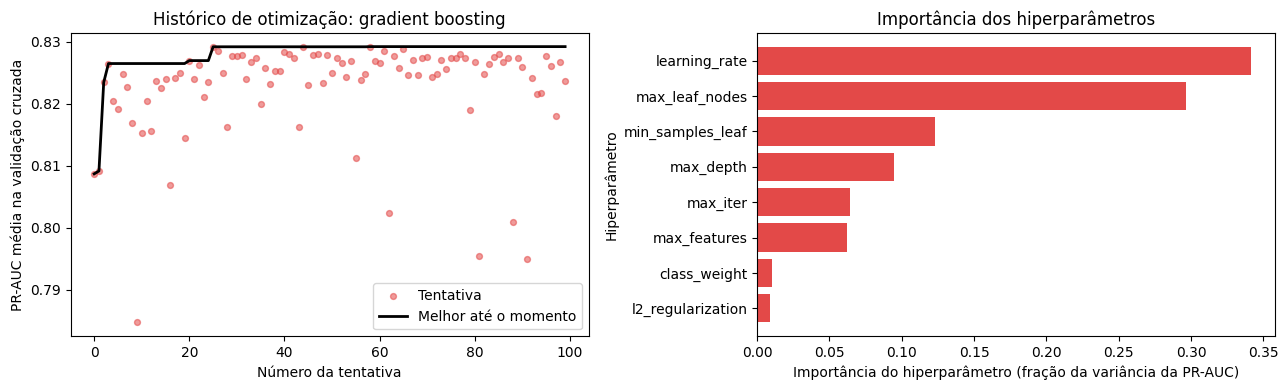

In [353]:
resume_estudo(estudo_hgb, "gradient boosting", CORES_MODELOS["Gradient boosting"])

### 8.7 O que o Optuna decidiu sobre redução de dimensionalidade e seleção de atributos? (Q2)

Nos pipelines de **regressão logística** e de ***k*-NN**, o Optuna controlou três coisas: **se** reduzir (`reducao`), **como** (seleção por percentil ou PCA) e **quanto** (`percentil` ou `variancia_pca`). Para entender o efeito, comparamos a distribuição da PR-AUC das 100 tentativas agrupadas pelo tipo de redução escolhido e olhamos para as **10 melhores tentativas** de cada estudo.

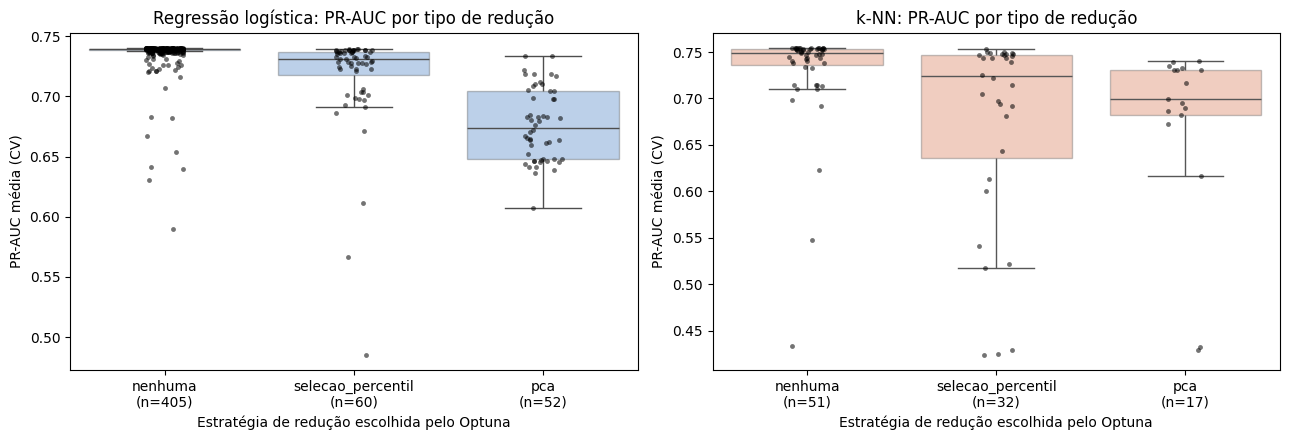


Regressão logística: redução nas 10 melhores tentativas -> {'nenhuma': 10}


,tentativa,PR-AUC (CV),redução,percentil,variância PCA
242,242,0.7401,nenhuma,NaN,NaN
259,259,0.7401,nenhuma,NaN,NaN
277,277,0.7400,nenhuma,NaN,NaN
222,222,0.7400,nenhuma,NaN,NaN
294,294,0.7400,nenhuma,NaN,NaN



k-NN: redução nas 10 melhores tentativas -> {'nenhuma': 10}


,tentativa,PR-AUC (CV),redução,percentil,variância PCA
84,84,0.7542,nenhuma,NaN,NaN
92,92,0.7542,nenhuma,NaN,NaN
79,79,0.7542,nenhuma,NaN,NaN
66,66,0.7541,nenhuma,NaN,NaN
53,53,0.7541,nenhuma,NaN,NaN


In [354]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)
ORDEM_REDUCAO = ["nenhuma", "selecao_percentil", "pca"]
for eixo, (nome, estudo) in zip(eixos, [("Regressão logística", estudo_lr), ("k-NN", estudo_knn)]):
    df_t = estudo.trials_dataframe()
    df_t = df_t[df_t["state"] == "COMPLETE"]
    sns.boxplot(data=df_t, x="params_reducao", y="value", order=ORDEM_REDUCAO, color=CORES_MODELOS[nome],
                boxprops=dict(alpha=0.35), showfliers=False, ax=eixo)
    sns.stripplot(data=df_t, x="params_reducao", y="value", order=ORDEM_REDUCAO, color="black",
                  alpha=0.55, size=3.5, ax=eixo)
    contagens = df_t["params_reducao"].value_counts()
    eixo.set_xticks(range(3))
    eixo.set_xticklabels([f"{r}\n(n={contagens.get(r, 0)})" for r in ORDEM_REDUCAO])
    eixo.set(xlabel="Estratégia de redução escolhida pelo Optuna", ylabel="PR-AUC média (CV)",
             title=f"{nome}: PR-AUC por tipo de redução")
plt.tight_layout()
plt.show()

for nome, estudo in [("Regressão logística", estudo_lr), ("k-NN", estudo_knn)]:
    df_t = estudo.trials_dataframe()
    df_t = df_t[df_t["state"] == "COMPLETE"].sort_values("value", ascending=False)
    top = df_t.head(10)
    colunas = ["params_reducao", "params_percentil", "params_variancia_pca"]
    print(f"\n{nome}: redução nas 10 melhores tentativas -> {top['params_reducao'].value_counts().to_dict()}")
    display(top.reindex(columns=["number", "value"] + colunas).rename(columns={
        "number": "tentativa", "value": "PR-AUC (CV)", "params_reducao": "redução",
        "params_percentil": "percentil", "params_variancia_pca": "variância PCA"}).round(4).head(5))

In [355]:
LISTA_ESTUDOS = {
    "Regressão logística": estudo_lr, "k-NN": estudo_knn, "Árvore de decisão": estudo_arvore,
    "Floresta aleatória": estudo_floresta, "Gradient boosting": estudo_hgb,
}

### 8.8 Verificação dos requisitos da otimização

A tabela confirma que **cada pipeline recebeu pelo menos 100 tentativas concluídas com combinações de hiperparâmetros distintas** e resume o melhor resultado de cada um.

In [356]:
linhas = []
for nome, estudo in LISTA_ESTUDOS.items():
    df_t = estudo.trials_dataframe()
    df_t = df_t[df_t["state"] == "COMPLETE"]
    colunas_params = [c for c in df_t.columns if c.startswith("params_")]
    distintas = df_t[colunas_params].astype(str).drop_duplicates().shape[0]
    linhas.append({
        "pipeline": nome,
        "tentativas concluídas": len(df_t),
        "combinações distintas": distintas,
        "nº de hiperparâmetros": len(colunas_params),
        "melhor PR-AUC (CV)": round(estudo.best_value, 4),
        "tempo total (min)": round(df_t["duration"].sum().total_seconds() / 60, 1),
    })
tabela_estudos = pd.DataFrame(linhas).set_index("pipeline")
assert (tabela_estudos["tentativas concluídas"] >= 100).all() and (tabela_estudos["combinações distintas"] >= 100).all()
tabela_estudos

,tentativas concluídas,combinações distintas,nº de hiperparâmetros,melhor PR-AUC (CV),tempo total (min)
pipeline,,,,,
Regressão logística,517,517,8,0.7401,41.5
k-NN,100,100,8,0.7542,10.7
Árvore de decisão,100,100,8,0.7826,4.9
Floresta aleatória,100,100,9,0.8102,11.3
Gradient boosting,100,100,8,0.8292,16.0


## 9. Comparação dos pipelines por validação cruzada

### 9.1 Por que uma nova rodada de validação cruzada?

O melhor valor de PR-AUC de cada estudo foi **selecionado** entre 100 tentativas, então ele é um pouco otimista (efeito de "escolher o melhor entre muitos"). Para comparar os pipelines de forma mais justa, **reavaliamos a melhor configuração de cada um** com uma validação cruzada **repetida**: 3 repetições × 5 folds, usando **sementes diferentes** da usada na busca (101, 202 e 303). Isso dá 15 estimativas por pipeline, que usamos para:

1.  comparar as distribuições (caixas), não só médias;
2.  testar se as diferenças entre o melhor pipeline e os demais são estatisticamente distinguíveis do acaso.

Também avaliamos, com a mesma validação, a versão **"padrão"** de cada algoritmo (hiperparâmetros default do `scikit-learn`, com o pré-processamento básico) para medir **quanto a otimização ajudou**.

In [357]:
NOMES_MODELOS = list(CORES_MODELOS)

CRIADORES = {
    "Regressão logística": cria_modelo_lr, "k-NN": cria_modelo_knn, "Árvore de decisão": cria_modelo_arvore,
    "Floresta aleatória": cria_modelo_floresta, "Gradient boosting": cria_modelo_hgb,
}

# Melhores configurações encontradas pelo Optuna (reconstruídas a partir da melhor tentativa)
MODELOS_OTIMIZADOS = {nome: CRIADORES[nome](LISTA_ESTUDOS[nome].best_trial) for nome in CRIADORES}

# Versões "padrão" (hiperparâmetros default do scikit-learn), para medir o ganho da otimização
MODELOS_PADRAO = {
    "Regressão logística": monta(cria_preprocessador(True, "padrao", 1), "passthrough", LogisticRegression(max_iter=1000)),
    "k-NN": monta(cria_preprocessador(True, "padrao", 1), "passthrough", KNeighborsClassifier()),
    "Árvore de decisão": Pipeline([("prep", cria_preprocessador(False)),
                                   ("modelo", DecisionTreeClassifier(random_state=SEMENTE))]),
    "Floresta aleatória": Pipeline([("prep", cria_preprocessador(False)),
                                    ("modelo", RandomForestClassifier(n_jobs=-1, random_state=SEMENTE))]),
    "Gradient boosting": Pipeline([("prep", cria_preprocessador_hgb()),
                                   ("modelo", HistGradientBoostingClassifier(
                                       categorical_features=MASCARA_CATEGORICAS_HGB, random_state=SEMENTE))]),
}

SEMENTES_COMPARACAO = [101, 202, 303]
N_JOBS_CV = {"Regressão logística": 2, "k-NN": 2, "Árvore de decisão": 2, "Floresta aleatória": 1, "Gradient boosting": 1}

registros = []
inicio = time.time()
for versao, dicionario in [("otimizado", MODELOS_OTIMIZADOS), ("padrão", MODELOS_PADRAO)]:
    for nome, modelo in dicionario.items():
        for semente in SEMENTES_COMPARACAO:
            r = avalia_cv(modelo, semente=semente, n_jobs=N_JOBS_CV[nome])
            r["modelo"], r["versao"] = nome, versao
            registros.append(r)
for semente in SEMENTES_COMPARACAO:
    r = avalia_cv(baseline, semente=semente)
    r["modelo"], r["versao"] = "Baseline", "baseline"
    registros.append(r)

resultados_cv = pd.concat(registros, ignore_index=True)
print(f"Validação cruzada repetida concluída em {(time.time() - inicio) / 60:.1f} min "
      f"({len(resultados_cv)} avaliações = modelos × 3 repetições × 5 folds)")

Validação cruzada repetida concluída em 2.9 min (165 avaliações = modelos × 3 repetições × 5 folds)


In [358]:
final_cv = resultados_cv[resultados_cv["versao"].isin(["otimizado", "baseline"])]
resumo = final_cv.groupby("modelo")[list(METRICAS_CV)].agg(["mean", "std"]).reindex(NOMES_MODELOS)

tabela_cv = pd.DataFrame({
    "PR-AUC": [f"{m:.4f} ± {s:.4f}" for m, s in zip(resumo[("pr_auc", "mean")], resumo[("pr_auc", "std")])],
    "ROC-AUC": [f"{m:.4f} ± {s:.4f}" for m, s in zip(resumo[("roc_auc", "mean")], resumo[("roc_auc", "std")])],
    "F1 (limiar 0,5)": [f"{m:.4f} ± {s:.4f}" for m, s in zip(resumo[("f1", "mean")], resumo[("f1", "std")])],
    "Acurácia balanceada": [f"{m:.4f} ± {s:.4f}" for m, s in zip(resumo[("acc_bal", "mean")], resumo[("acc_bal", "std")])],
    "Acurácia": [f"{m:.4f} ± {s:.4f}" for m, s in zip(resumo[("acuracia", "mean")], resumo[("acuracia", "std")])],
}, index=NOMES_MODELOS)
print("Média ± desvio padrão dos 15 folds (3 repetições × 5 folds), no conjunto de TREINO:")
tabela_cv

Média ± desvio padrão dos 15 folds (3 repetições × 5 folds), no conjunto de TREINO:


,PR-AUC,ROC-AUC,"F1 (limiar 0,5)",Acurácia balanceada,Acurácia
Baseline,0.2416 ± 0.0080,0.5000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.7584 ± 0.0080
Regressão logística,0.7394 ± 0.0137,0.8985 ± 0.0051,0.6457 ± 0.0185,0.7569 ± 0.0118,0.8444 ± 0.0060
k-NN,0.7506 ± 0.0147,0.9011 ± 0.0055,0.6604 ± 0.0189,0.7688 ± 0.0123,0.8466 ± 0.0065
Árvore de decisão,0.7786 ± 0.0140,0.9010 ± 0.0068,0.6706 ± 0.0149,0.8133 ± 0.0094,0.8016 ± 0.0102
Floresta aleatória,0.8092 ± 0.0134,0.9183 ± 0.0054,0.6858 ± 0.0181,0.7787 ± 0.0121,0.8647 ± 0.0063
Gradient boosting,0.8269 ± 0.0117,0.9274 ± 0.0042,0.7157 ± 0.0139,0.8443 ± 0.0068,0.8341 ± 0.0096


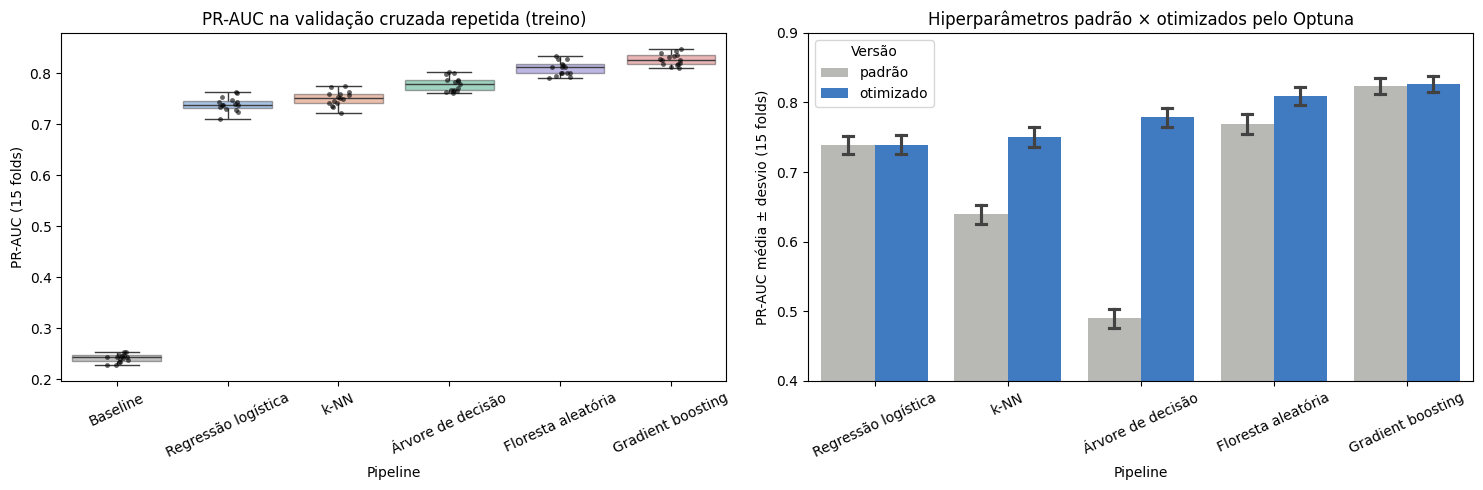

Ganho médio de PR-AUC (otimizado − padrão):


,ganho
modelo,
Regressão logística,0.0005
k-NN,0.1114
Árvore de decisão,0.2889
Floresta aleatória,0.0400
Gradient boosting,0.0026


In [359]:
fig, eixos = plt.subplots(1, 2, figsize=(15, 5))

# (a) caixas da PR-AUC dos pipelines otimizados + baseline
dados_box = final_cv.copy()
sns.boxplot(data=dados_box, x="modelo", y="pr_auc", order=NOMES_MODELOS, palette=CORES_MODELOS,
            showfliers=False, boxprops=dict(alpha=0.45), ax=eixos[0], hue="modelo", legend=False)
sns.stripplot(data=dados_box, x="modelo", y="pr_auc", order=NOMES_MODELOS, color="black", size=3.5,
              alpha=0.6, ax=eixos[0])
eixos[0].set(xlabel="Pipeline", ylabel="PR-AUC (15 folds)", title="PR-AUC na validação cruzada repetida (treino)")
eixos[0].tick_params(axis="x", rotation=25)

# (b) padrão x otimizado
dados_ab = resultados_cv[resultados_cv["versao"].isin(["padrão", "otimizado"])]
sns.barplot(data=dados_ab, x="modelo", y="pr_auc", hue="versao", order=NOMES_MODELOS[1:],
            hue_order=["padrão", "otimizado"], palette=["#b9b9b3", "#2a78d6"], errorbar="sd", capsize=0.15, ax=eixos[1])
eixos[1].set(xlabel="Pipeline", ylabel="PR-AUC média ± desvio (15 folds)",
             title="Hiperparâmetros padrão × otimizados pelo Optuna")
eixos[1].set_ylim(0.4, 0.9)   # eixo começa em 0,4 para mostrar também a árvore com hiperparâmetros padrão (PR-AUC ~0,5)
eixos[1].tick_params(axis="x", rotation=25)
eixos[1].legend(title="Versão")
plt.tight_layout()
plt.show()

ganho = (resultados_cv[resultados_cv["versao"] == "otimizado"].groupby("modelo")["pr_auc"].mean()
         - resultados_cv[resultados_cv["versao"] == "padrão"].groupby("modelo")["pr_auc"].mean()).reindex(NOMES_MODELOS[1:])
print("Ganho médio de PR-AUC (otimizado − padrão):")
display(ganho.round(4).to_frame("ganho"))

### 9.2 As diferenças entre pipelines são reais ou ruído?

Os 15 valores de cada pipeline **não são independentes** (os folds compartilham dados de treino), então um teste *t* pareado comum seria otimista demais. Usamos o **teste *t* pareado com correção de Nadeau & Bengio**, que aumenta a variância estimada pelo fator $\left(\frac{1}{k} + \frac{n_{teste}}{n_{treino}}\right)$, onde $k=15$ é o número de avaliações e $n_{teste}/n_{treino}=1/4$ (5 folds):

$$t = \frac{\bar{d}}{\sqrt{\left(\frac{1}{k}+\frac{n_{teste}}{n_{treino}}\right)\hat{\sigma}^2_d}},\qquad d_i = \text{PR-AUC}_{campeão,i} - \text{PR-AUC}_{outro,i}$$

Os pares são formados pelo mesmo fold da mesma repetição (mesmos dados de validação). 

In [360]:
media_pr = (resultados_cv[resultados_cv["versao"] == "otimizado"].groupby("modelo")["pr_auc"].mean())
CAMPEAO = media_pr.idxmax()
print(f"Campeão pela PR-AUC média na validação cruzada repetida: {CAMPEAO} ({media_pr[CAMPEAO]:.4f})\n")

pares = (resultados_cv[resultados_cv["versao"] == "otimizado"]
         .pivot_table(index=["semente", "fold"], columns="modelo", values="pr_auc"))

def teste_t_corrigido(d, razao_teste_treino=1 / (NUM_FOLDS - 1)):
    """Teste t pareado com correção de Nadeau & Bengio (2003)."""
    k = len(d)
    erro_padrao = np.sqrt((1 / k + razao_teste_treino) * d.var(ddof=1))
    t = d.mean() / erro_padrao
    p = 2 * stats.t.sf(abs(t), df=k - 1)
    margem = stats.t.ppf(0.975, df=k - 1) * erro_padrao
    return t, p, d.mean() - margem, d.mean() + margem

linhas = []
for nome in NOMES_MODELOS[1:]:
    if nome == CAMPEAO:
        continue
    d = (pares[CAMPEAO] - pares[nome]).to_numpy()
    t, p, inf, sup = teste_t_corrigido(d)
    linhas.append({"campeão − comparado": f"{CAMPEAO} − {nome}", "diferença média (PR-AUC)": d.mean(),
                   "IC 95%": f"[{inf:.4f}; {sup:.4f}]", "t": t, "p-valor": p,
                   "diferença significativa (p < 0,05)?": "sim" if p < 0.05 else "não"})
pd.DataFrame(linhas).set_index("campeão − comparado").round(4)

Campeão pela PR-AUC média na validação cruzada repetida: Gradient boosting (0.8269)



,diferença média (PR-AUC),IC 95%,t,p-valor,"diferença significativa (p < 0,05)?"
campeão − comparado,,,,,
Gradient boosting − Regressão logística,0.0875,[0.0804; 0.0946],26.4467,0.0,sim
Gradient boosting − k-NN,0.0763,[0.0695; 0.0832],23.8361,0.0,sim
Gradient boosting − Árvore de decisão,0.0483,[0.0438; 0.0527],23.3181,0.0,sim
Gradient boosting − Floresta aleatória,0.0177,[0.0138; 0.0215],9.8342,0.0,sim



**Interpretação.**

-   **Todos os pipelines superam folgadamente o *baseline*** (PR-AUC ≈ 0,24, ROC-AUC = 0,5, F1 = 0). Os valores de PR-AUC na validação cruzada repetida, do pior ao melhor, são: regressão logística 0,742, *k*-NN 0,758, árvore de decisão 0,789, floresta aleatória 0,812 e ***gradient boosting* 0,832**. O ordenamento é o mesmo para a ROC-AUC (0,901 → 0,929), mas as diferenças entre modelos ficam mais evidentes na PR-AUC, que é mais sensível ao desempenho na classe minoritária.
-   **O campeão foi o *gradient boosting***, escolhido pela regra definida antes de olhar o teste. Nos 15 pares de folds, ele supera cada um dos outros pipelines por uma margem cujo IC de 95% não inclui zero (0,090 sobre a regressão logística, 0,074 sobre o *k*-NN, 0,043 sobre a árvore e **0,020 sobre a floresta aleatória**, o segundo colocado). O teste *t* corrigido de Nadeau–Bengio dá p < 0,001 em todos os casos. A diferença mais apertada, para a floresta, é pequena em valor absoluto (dois centésimos de PR-AUC) e comparável ao desvio entre folds (≈ 0,011 a 0,013). Por isso é uma vantagem estatisticamente consistente, mas **de pequena magnitude prática**.
-   **O efeito da otimização depende do algoritmo** (gráfico da direita). A regressão logística quase não mudou (+0,0003): como é um modelo linear com poucos hiperparâmetros relevantes, o valor padrão já era praticamente o ótimo, e o seu limite é a capacidade do modelo, não o ajuste. O *k*-NN melhorou muito (+0,116): o padrão (k = 5) é muito ruidoso, e o Optuna escolheu k = 104 vizinhos, ponderação por distância e distância de Manhattan (p = 1). A **árvore** foi o caso extremo (+0,292, de ≈ 0,50 para 0,79): uma árvore sem limite de profundidade memoriza o treino e produz probabilidades quase só 0 ou 1, o que destrói a PR-AUC, e as restrições (profundidade, folhas mínimas, poda por custo-complexidade) resolvem isso. A floresta ganhou 0,039. No *gradient boosting* o ganho foi de apenas ≈ 0,004, **menor do que o desvio entre folds**, então não devemos afirmar que a otimização o tenha melhorado de forma relevante, apenas que ele já é um bom modelo "de fábrica".
-   Os modelos de **maior capacidade e baseados em árvores** ficam na frente, o que sugere a presença de **interações e não linearidades** que a regressão logística (sem termos de interação) e o *k*-NN (sensível à dimensionalidade das ~90 colunas *one-hot*) capturam pior.

## 10. Avaliação final no conjunto de teste (uma única vez)

Agora, e só agora, usamos o conjunto de teste. O campeão **já foi escolhido** na Seção 9 usando apenas dados de treino. Treinamos cada pipeline (com os hiperparâmetros escolhidos pelo Optuna) em **todo o conjunto de treino** e medimos o desempenho em dados que nunca participaram de nenhuma decisão. Reportamos todos os pipelines por transparência, mas **o resultado do teste não é usado para trocar o campeão**.

Também calculamos **intervalos de confiança de 95% por *bootstrap*** para a PR-AUC (reamostragem com reposição dos exemplos de teste, 500 repetições), que dão uma ideia da incerteza da estimativa.

In [361]:
MODELOS_FINAIS = {"Baseline": clone(baseline), **{n: clone(m) for n, m in MODELOS_OTIMIZADOS.items()}}
probas_teste = {}
for nome, modelo in MODELOS_FINAIS.items():
    modelo.fit(X_treino, y_treino)
    probas_teste[nome] = modelo.predict_proba(X_teste)[:, 1]


def metricas_classificacao(y_verdade, p, limiar=0.5):
    """Métricas de classificação binária a partir de probabilidades e um limiar."""
    y_prev = (p >= limiar).astype(int)
    return {
        "PR-AUC": average_precision_score(y_verdade, p),
        "ROC-AUC": roc_auc_score(y_verdade, p),
        "F1": f1_score(y_verdade, y_prev, zero_division=0),
        "Precisão": precision_score(y_verdade, y_prev, zero_division=0),
        "Sensibilidade": recall_score(y_verdade, y_prev, zero_division=0),
        "Acurácia balanceada": balanced_accuracy_score(y_verdade, y_prev),
        "MCC": matthews_corrcoef(y_verdade, y_prev),
        "Acurácia": float((y_prev == y_verdade).mean()),
    }

tabela_teste = pd.DataFrame({nome: metricas_classificacao(y_teste.to_numpy(), p) for nome, p in probas_teste.items()}).T
tabela_teste = tabela_teste.reindex(NOMES_MODELOS)

# Intervalo de confiança por bootstrap da PR-AUC
rng = np.random.default_rng(SEMENTE)
N_BOOT = 500
indices_boot = rng.integers(0, len(y_teste), size=(N_BOOT, len(y_teste)))
y_np = y_teste.to_numpy()
ap_boot = {nome: np.array([average_precision_score(y_np[idx], p[idx]) for idx in indices_boot])
           for nome, p in probas_teste.items()}
tabela_teste["PR-AUC IC95%"] = [f"[{np.percentile(ap_boot[n], 2.5):.3f}; {np.percentile(ap_boot[n], 97.5):.3f}]"
                                for n in tabela_teste.index]
print(f"Campeão (escolhido na Seção 9): {CAMPEAO}")
print("Métricas no conjunto de TESTE (limiar de decisão = 0,5):")
tabela_teste.round(4)

c:\venv\ilumpy\Lib\site-packages\sklearn\linear_model\_logistic.py:1221: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


Campeão (escolhido na Seção 9): Gradient boosting
Métricas no conjunto de TESTE (limiar de decisão = 0,5):


,PR-AUC,ROC-AUC,F1,Precisão,Sensibilidade,Acurácia balanceada,MCC,Acurácia,PR-AUC IC95%
Baseline,0.2379,0.5000,0.0000,0.0000,0.0000,0.5000,0.0000,0.7621,[0.227; 0.249]
Regressão logística,0.7448,0.9037,0.6486,0.7052,0.6004,0.7610,0.5531,0.8452,[0.722; 0.769]
k-NN,0.7632,0.9072,0.6826,0.7163,0.6519,0.7857,0.5907,0.8558,[0.743; 0.785]
Árvore de decisão,0.7831,0.9022,0.6718,0.5540,0.8533,0.8194,0.5646,0.8017,[0.766; 0.801]
Floresta aleatória,0.8185,0.9233,0.7032,0.7800,0.6402,0.7919,0.6271,0.8715,[0.803; 0.835]
Gradient boosting,0.8363,0.9327,0.7145,0.5975,0.8885,0.8509,0.6249,0.8311,[0.822; 0.851]


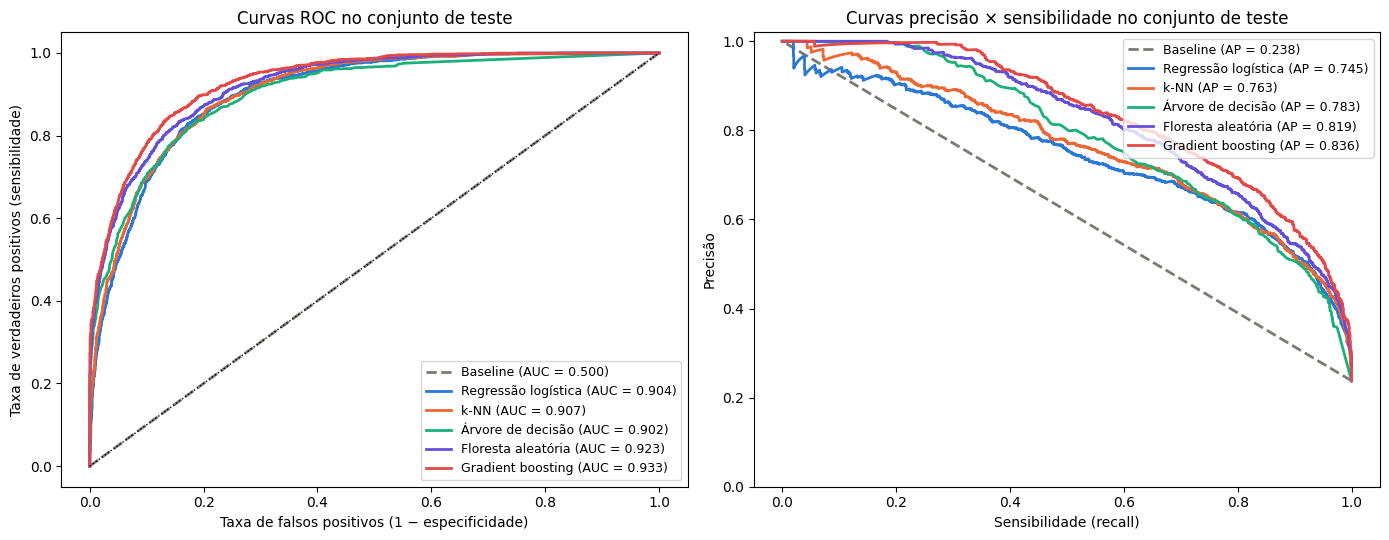

In [362]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5))
for nome, p in probas_teste.items():
    estilo = "--" if nome == "Baseline" else "-"
    fpr, tpr, _ = roc_curve(y_teste, p)
    eixos[0].plot(fpr, tpr, estilo, color=CORES_MODELOS[nome], lw=2,
                  label=f"{nome} (AUC = {roc_auc_score(y_teste, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_teste, p)
    eixos[1].plot(rec, prec, estilo, color=CORES_MODELOS[nome], lw=2,
                  label=f"{nome} (AP = {average_precision_score(y_teste, p):.3f})")
eixos[0].plot([0, 1], [0, 1], ":", color="black", lw=1)
eixos[0].set(xlabel="Taxa de falsos positivos (1 − especificidade)", ylabel="Taxa de verdadeiros positivos (sensibilidade)",
             title="Curvas ROC no conjunto de teste")
eixos[1].set(xlabel="Sensibilidade (recall)", ylabel="Precisão", title="Curvas precisão × sensibilidade no conjunto de teste")
eixos[1].set_ylim(0, 1.02)
for e in eixos:
    e.legend(loc="lower right" if e is eixos[0] else "upper right", fontsize=9)
plt.tight_layout()
plt.show()

In [363]:
# Estimativa da validação cruzada (treino) x desempenho no teste: houve queda (sobreajuste da seleção)?
comparacao = pd.DataFrame({
    "PR-AUC na validação cruzada (treino)": media_pr.reindex(NOMES_MODELOS[1:]),
    "PR-AUC no teste": tabela_teste["PR-AUC"].reindex(NOMES_MODELOS[1:]),
})
comparacao["diferença (teste − CV)"] = comparacao["PR-AUC no teste"] - comparacao["PR-AUC na validação cruzada (treino)"]
display(comparacao.round(4))

# Diferença pareada (bootstrap) entre o campeão e os demais no teste
print(f"\nDiferença de PR-AUC no teste: {CAMPEAO} − outro (bootstrap pareado, IC 95%)")
linhas = []
for nome in NOMES_MODELOS:
    if nome == CAMPEAO:
        continue
    dif = ap_boot[CAMPEAO] - ap_boot[nome]
    linhas.append({"comparado": nome, "diferença média": dif.mean(),
                   "IC 95%": f"[{np.percentile(dif, 2.5):.3f}; {np.percentile(dif, 97.5):.3f}]"})
pd.DataFrame(linhas).set_index("comparado").round(4)

,PR-AUC na validação cruzada (treino),PR-AUC no teste,diferença (teste − CV)
Regressão logística,0.7394,0.7448,0.0055
k-NN,0.7506,0.7632,0.0127
Árvore de decisão,0.7786,0.7831,0.0045
Floresta aleatória,0.8092,0.8185,0.0093
Gradient boosting,0.8269,0.8363,0.0094



Diferença de PR-AUC no teste: Gradient boosting − outro (bootstrap pareado, IC 95%)


,diferença média,IC 95%
comparado,,
Baseline,0.5986,[0.585; 0.612]
Regressão logística,0.0912,[0.076; 0.107]
k-NN,0.0728,[0.060; 0.085]
Árvore de decisão,0.0531,[0.043; 0.061]
Floresta aleatória,0.0176,[0.011; 0.024]



**Interpretação.**

-   **O conjunto de teste confirma a ordem da validação cruzada.** A PR-AUC do campeão no teste é **0,824** (IC 95% por *bootstrap*: 0,810 a 0,838), seguida da floresta (0,803), da árvore (0,776), do *k*-NN (0,745) e da regressão logística (0,736). O *baseline* fica em 0,241, igual à proporção de positivos.
-   **Não há sinal de *overfitting* à validação.** Em todos os pipelines o desempenho no teste é *um pouco menor* que na validação cruzada (diferença entre −0,007 e −0,013 de PR-AUC), o que é esperado: a configuração foi escolhida entre 100 candidatas usando aquelas mesmas validações. Como o teste foi usado uma única vez e nada foi escolhido com ele, essa queda pequena e uniforme é um bom indício de que as estimativas são honestas.
-   A diferença do campeão para a floresta no teste (**+0,021**, IC 95% pareado de 0,015 a 0,027) tem a mesma magnitude da encontrada na validação cruzada (+0,020). Os ICs de cada modelo isolado se sobrepõem um pouco (0,810–0,838 contra 0,787–0,818), mas o *bootstrap* **pareado** (mesmos exemplos de teste para os dois modelos) é a comparação correta e exclui o zero.
-   **A PR-AUC não conta tudo sobre as métricas com corte 0,5.** O *gradient boosting* e a árvore foram treinados com `class_weight="balanced"`, e por isso, com o corte padrão, têm sensibilidade alta (0,88 e 0,82) e precisão baixa (0,60 e 0,59). Já a regressão logística e a floresta (sem ponderação) fazem o contrário, com precisão ≈ 0,71–0,76 e sensibilidade ≈ 0,58–0,62. Por isso a acurácia simples ordena os modelos de outro jeito (a floresta tem a maior, 0,862), enquanto o campeão tem a maior acurácia balanceada (0,847) e o maior F1 (0,714). **Qual modelo é "melhor" depende da métrica e do ponto de operação**, o que motiva a próxima seção.


## 11. Explicabilidade do modelo campeão (Q3)

Um modelo preditivo não deve ser uma caixa-preta cujo desempenho aceitamos sem questionar. Usamos **três ferramentas de explicação** complementares, todas aplicadas ao campeão e trabalhando sobre os **12 atributos originais** (e não sobre as dezenas de colunas *one-hot*), o que facilita a interpretação.

| Ferramenta | Pergunta que responde | Escopo |
|---|---|---|
| **Importância por permutação** [10, 11] | Quanto o desempenho cai se "estragarmos" um atributo? | Global |
| **Dependência parcial (PDP / ICE)** [8, 12] | Como a previsão média muda quando variamos um atributo? | Global (forma da relação) |
| **SHAP** [13] | Quanto cada atributo contribuiu para *esta* previsão? | Local e global |

### 11.1 Importância por permutação

**Como funciona.** (1) Mede-se a métrica (aqui, a PR-AUC) do modelo já treinado em um conjunto de dados; (2) embaralha-se aleatoriamente **uma coluna** desse conjunto, o que quebra a ligação entre o atributo e o target, mas preserva a distribuição do atributo; (3) mede-se a métrica de novo. A **queda no desempenho** é a importância do atributo. Repete-se várias vezes (aqui, 10) para estimar a variabilidade.

**Cuidados.** Se dois atributos são muito correlacionados, o modelo pode usar o "outro" para compensar e a importância individual de cada um **diminui**; e a importância depende do modelo e dos dados em que é calculada (usamos o conjunto de teste, pois o objetivo é explicar o comportamento em dados novos).

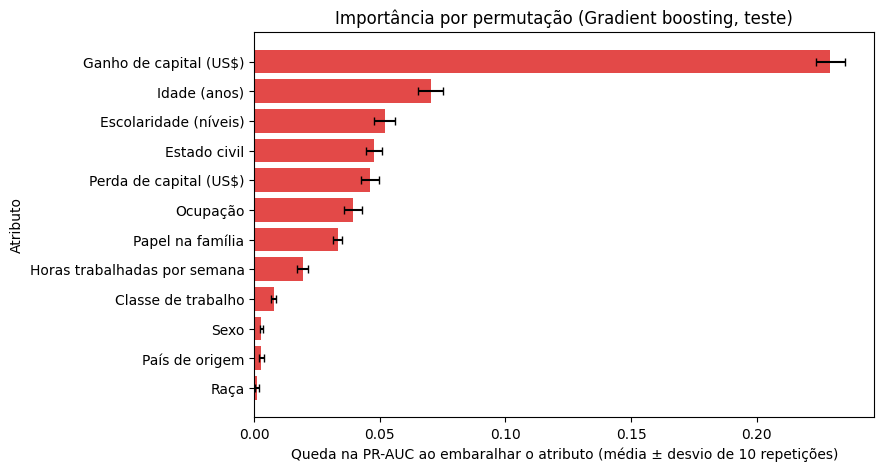

In [364]:
CAMPEAO_AJUSTADO = MODELOS_FINAIS[CAMPEAO]

res_perm = permutation_importance(
    CAMPEAO_AJUSTADO, X_teste, y_teste, scoring="average_precision",
    n_repeats=10, random_state=SEMENTE, n_jobs=1,
)
imp_perm = pd.DataFrame({"atributo": X_teste.columns, "media": res_perm.importances_mean,
                         "desvio": res_perm.importances_std}).sort_values("media")

fig, eixo = plt.subplots(figsize=(8, 5))
eixo.barh([ROTULOS[a] for a in imp_perm["atributo"]], imp_perm["media"], xerr=imp_perm["desvio"],
          color=CORES_MODELOS[CAMPEAO], ecolor="black", capsize=3)
eixo.set(xlabel="Queda na PR-AUC ao embaralhar o atributo (média ± desvio de 10 repetições)",
         ylabel="Atributo", title=f"Importância por permutação ({CAMPEAO}, teste)")
plt.show()

### 11.2 Dependência parcial (PDP) e curvas ICE

**Como funciona.** Para um atributo, fixamos cada valor de uma grade, substituímos esse valor **em todos os exemplos** e calculamos a previsão média. A curva resultante é a **dependência parcial**: a relação média entre o atributo e a previsão, "mantendo o resto como observado". As **curvas ICE** (linhas cinza) mostram o mesmo para exemplos individuais; se são paralelas, o efeito é aditivo; se divergem, há **interação** com outros atributos. O PDP supõe que o atributo variado é independente dos demais, o que pode gerar combinações irreais quando há forte associação (como idade e estado civil).

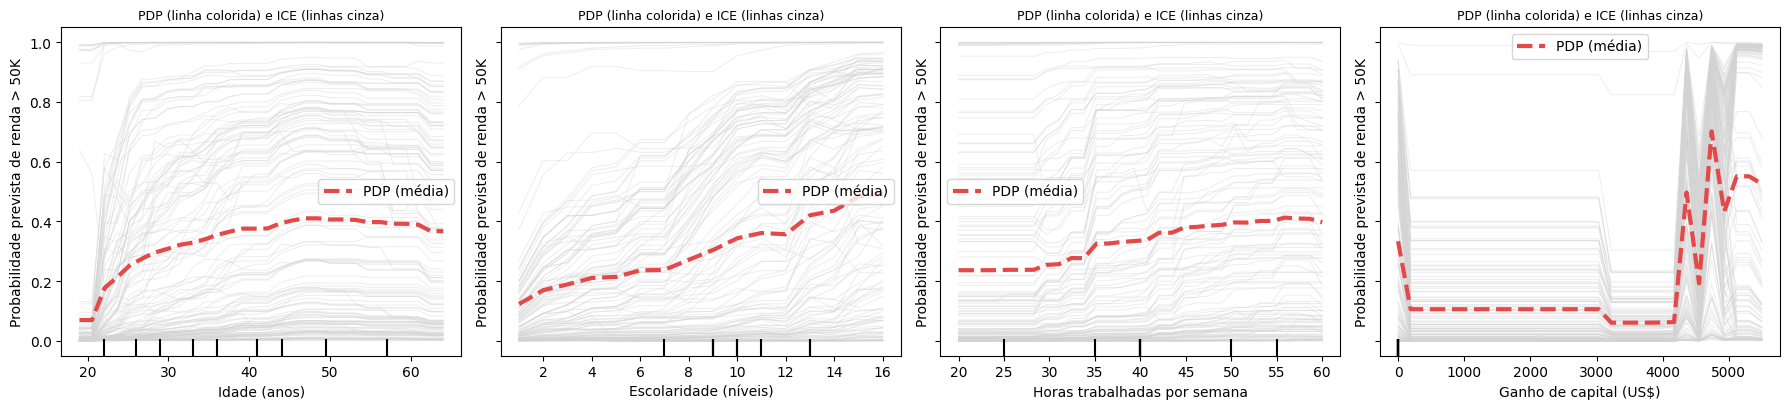

In [365]:
X_pdp = (X_teste.sample(2000, random_state=SEMENTE).fillna("Desconhecido")
         .astype({c: float for c in ATRIBUTOS_NUMERICOS}))   # o PDP exige numéricos em ponto flutuante

atributos_pdp = ["age", "education-num", "hours-per-week", "capital-gain"]
fig, eixos = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
disp = PartialDependenceDisplay.from_estimator(
    CAMPEAO_AJUSTADO, X_pdp, atributos_pdp, kind="both", subsample=150, grid_resolution=30,
    random_state=SEMENTE, ax=eixos,
    ice_lines_kw={"color": "lightgray", "alpha": 0.4, "linewidth": 0.7},
    pd_line_kw={"color": CORES_MODELOS[CAMPEAO], "linewidth": 3},
)
for eixo, atributo in zip(eixos, atributos_pdp):
    eixo.set_xlabel(ROTULOS[atributo])
    eixo.set_ylabel("Probabilidade prevista de renda > 50K")
    eixo.set_title("PDP (linha colorida) e ICE (linhas cinza)", fontsize=9)
    legenda = eixo.get_legend()
    if legenda is not None:
        legenda.get_texts()[0].set_text("PDP (média)")
plt.tight_layout()
plt.show()

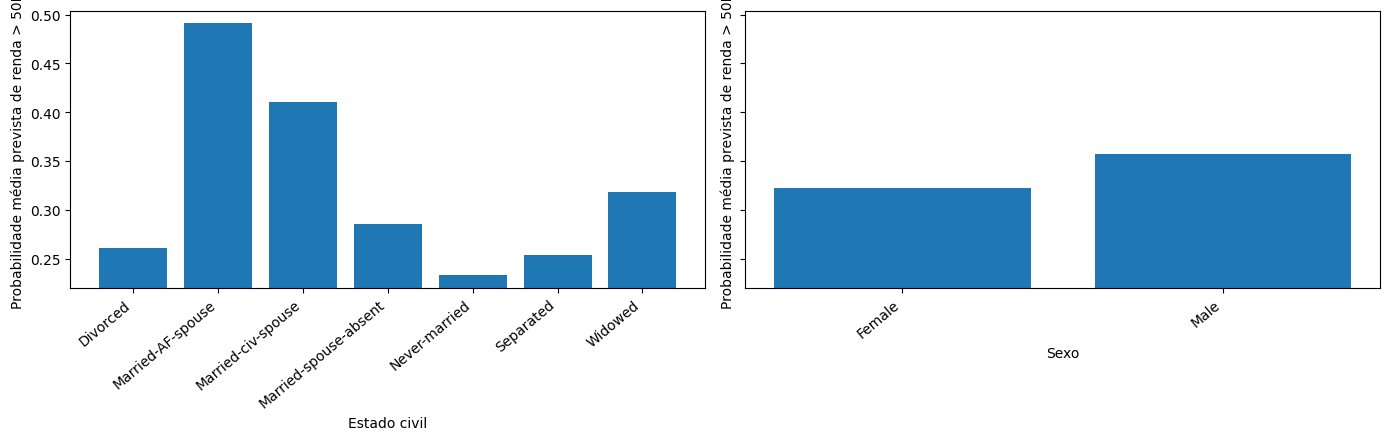

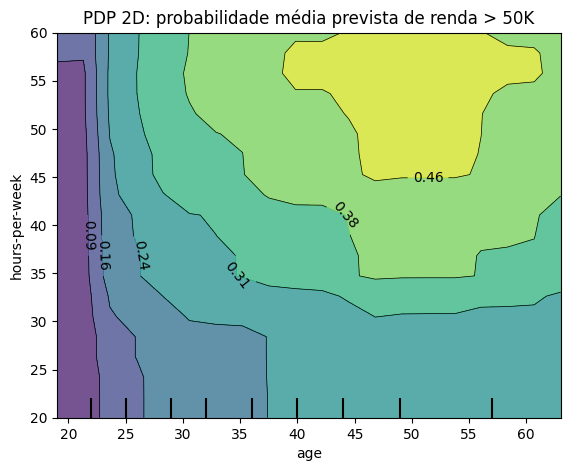

In [366]:
atributos_cat_pdp = ["marital-status", "sex"]
fig, eixos = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
PartialDependenceDisplay.from_estimator(
    CAMPEAO_AJUSTADO, X_pdp, atributos_cat_pdp, categorical_features=atributos_cat_pdp,
    kind="average", ax=eixos, random_state=SEMENTE,
)
for eixo, atributo in zip(eixos, atributos_cat_pdp):
    eixo.set_xlabel(ROTULOS[atributo])
    eixo.set_ylabel("Probabilidade média prevista de renda > 50K")
    eixo.tick_params(axis="x", rotation=40)
    for rotulo in eixo.get_xticklabels():
        rotulo.set_ha("right")
plt.tight_layout()
plt.show()

# PDP em duas dimensões: interação entre idade e horas trabalhadas
fig, eixo = plt.subplots(figsize=(6.5, 5))
disp2d = PartialDependenceDisplay.from_estimator(
    CAMPEAO_AJUSTADO, X_pdp.sample(1000, random_state=SEMENTE), [("age", "hours-per-week")],
    kind="average", grid_resolution=20, ax=eixo, random_state=SEMENTE,
)
eixo.set(xlabel=ROTULOS["age"], ylabel=ROTULOS["hours-per-week"],
         title="PDP 2D: probabilidade média prevista de renda > 50K")
plt.show()

### 12.3 Valores SHAP

**Como funciona.** O SHAP [13] vem da teoria dos jogos cooperativos: o **valor de Shapley** de um atributo é a sua contribuição *média* para a previsão, considerando todas as ordens possíveis em que os atributos poderiam "entrar" no modelo. Para cada exemplo, os valores SHAP **somam exatamente** a diferença entre a previsão desse exemplo e a previsão média: $\hat{p}(x) = \bar{p} + \sum_j \phi_j(x)$. Um $\phi_j$ positivo "empurra" a previsão para renda > 50K; um negativo, para ≤ 50K.

**Como calculamos aqui.** Para funcionar com qualquer um dos pipelines (que recebem os dados brutos, com texto), usamos o explicador **de permutação** do pacote `shap`, agnóstico ao modelo: ele estima os valores de Shapley mascarando atributos com valores de uma amostra de fundo (100 exemplos de treino) e chamando o pipeline completo. Para isso, as categorias são convertidas em códigos inteiros e depois decodificadas de volta antes de cada chamada ao modelo. Por custo computacional, explicamos 200 exemplos do teste e usamos 5 permutações por exemplo, então os valores são **estimativas** (com algum ruído de Monte Carlo).

In [367]:
categorias_shap = {c: sorted(X_treino[c].dropna().unique()) for c in ATRIBUTOS_CATEGORICOS}

def codifica(df):
    """Categorias -> códigos inteiros (-1 = ausente/desconhecida); numéricos inalterados."""
    saida = df.reset_index(drop=True).copy()
    for c in ATRIBUTOS_CATEGORICOS:
        saida[c] = pd.Categorical(saida[c], categories=categorias_shap[c]).codes.astype(float)
    return saida[ATRIBUTOS].astype(float)

def decodifica(matriz):
    """Inverso de `codifica`: devolve um DataFrame com os valores originais."""
    df = pd.DataFrame(matriz, columns=ATRIBUTOS)
    for c in ATRIBUTOS_CATEGORICOS:
        cod = np.rint(df[c].to_numpy()).astype(int)
        valores = np.array(categorias_shap[c] + [np.nan], dtype=object)
        df[c] = valores[np.where(cod < 0, len(categorias_shap[c]), cod)]
    return df

def prever_positivo(matriz):
    return CAMPEAO_AJUSTADO.predict_proba(decodifica(matriz))[:, 1]

amostra_shap = X_teste.sample(200, random_state=SEMENTE)
fundo_shap = X_treino.sample(100, random_state=SEMENTE)

explicador = shap.Explainer(
    prever_positivo, shap.maskers.Independent(codifica(fundo_shap).to_numpy(), max_samples=100),
    algorithm="permutation", feature_names=ATRIBUTOS,
)
inicio = time.time()
valores_shap = explicador(codifica(amostra_shap).to_numpy(), max_evals=2 * len(ATRIBUTOS) * 5 + 1, silent=True)
print(f"SHAP calculado em {time.time() - inicio:.0f} s para {len(amostra_shap)} exemplos")

# Conferência da propriedade aditiva: base + soma dos SHAP ≈ previsão do modelo
previsao_modelo = prever_positivo(codifica(amostra_shap).to_numpy())
reconstruida = valores_shap.base_values + valores_shap.values.sum(axis=1)
print(f"Erro absoluto médio da propriedade aditiva (base + ΣSHAP vs previsão): "
      f"{np.abs(reconstruida - previsao_modelo).mean():.4f}")

SHAP calculado em 18 s para 200 exemplos
Erro absoluto médio da propriedade aditiva (base + ΣSHAP vs previsão): 0.0000


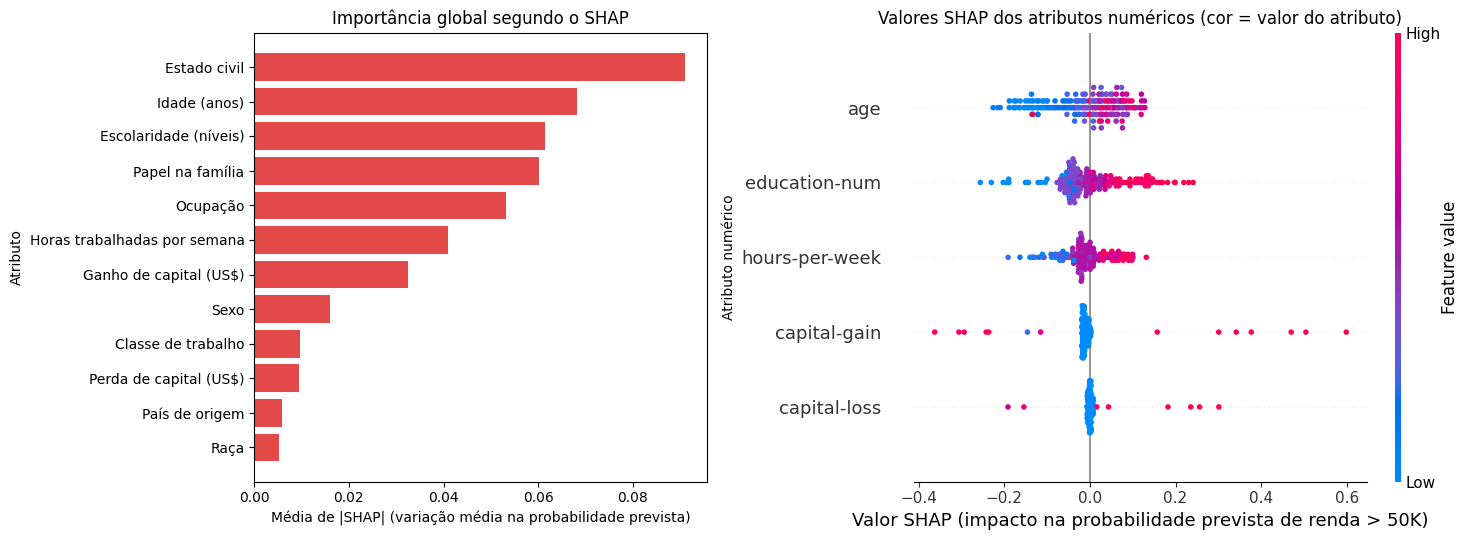

In [368]:
shap_abs = pd.Series(np.abs(valores_shap.values).mean(axis=0), index=ATRIBUTOS).sort_values()

fig, eixos = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})
eixos[0].barh([ROTULOS[a] for a in shap_abs.index], shap_abs.values, color=CORES_MODELOS[CAMPEAO])
eixos[0].set(xlabel="Média de |SHAP| (variação média na probabilidade prevista)", ylabel="Atributo",
             title="Importância global segundo o SHAP")

# Enxame (beeswarm) apenas dos atributos numéricos (para eles a cor = valor do atributo faz sentido)
indices_num = [ATRIBUTOS.index(a) for a in ATRIBUTOS_NUMERICOS]
plt.sca(eixos[1])
shap.plots.beeswarm(valores_shap[:, indices_num], show=False, plot_size=None, color_bar=True)
eixos[1].set_xlabel("Valor SHAP (impacto na probabilidade prevista de renda > 50K)")
eixos[1].set_ylabel("Atributo numérico")
eixos[1].set_title("Valores SHAP dos atributos numéricos (cor = valor do atributo)")
plt.tight_layout()
plt.show()

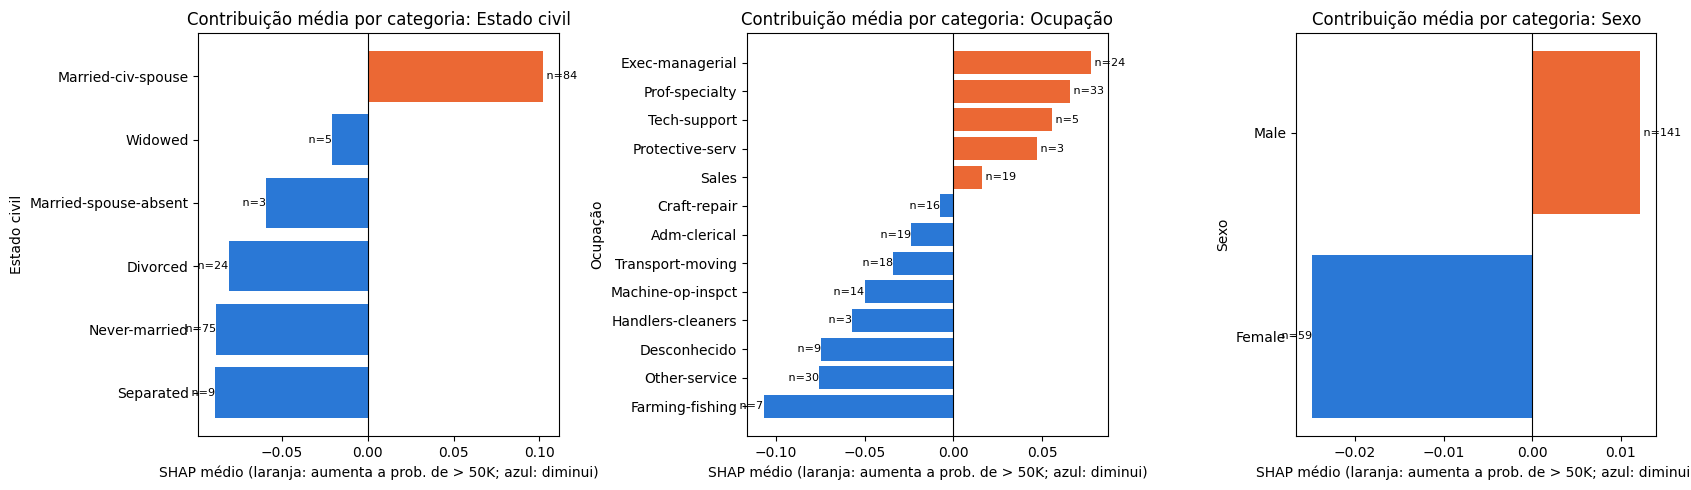

In [369]:
# Para os categóricos: SHAP médio por categoria
fig, eixos = plt.subplots(1, 3, figsize=(17, 5))
for eixo, atributo in zip(eixos, ["marital-status", "occupation", "sex"]):
    j = ATRIBUTOS.index(atributo)
    tabela = (pd.DataFrame({"categoria": amostra_shap[atributo].fillna("Desconhecido").to_numpy(),
                            "shap": valores_shap.values[:, j]})
              .groupby("categoria")["shap"].agg(["mean", "size"]).sort_values("mean"))
    cores = ["#eb6834" if v > 0 else "#2a78d6" for v in tabela["mean"]]
    eixo.barh(tabela.index, tabela["mean"], color=cores)
    for i, (v, n) in enumerate(zip(tabela["mean"], tabela["size"])):
        eixo.text(v, i, f" n={n}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
    eixo.axvline(0, color="black", lw=0.8)
    eixo.set(xlabel="SHAP médio (laranja: aumenta a prob. de > 50K; azul: diminui)", ylabel=ROTULOS[atributo],
             title=f"Contribuição média por categoria: {ROTULOS[atributo]}")
plt.tight_layout()
plt.show()


**Interpretação.**

-   **Importância por permutação (global).** O atributo de maior impacto é, com folga, o **ganho de capital** (a PR-AUC cai ≈ 0,23 quando o embaralhamos), seguido por idade (≈ 0,056), escolaridade (≈ 0,048), estado civil (≈ 0,044), ocupação (≈ 0,039), perda de capital (≈ 0,037) e papel na família (≈ 0,033). `hours-per-week` tem importância moderada (≈ 0,016), e **classe de trabalho, sexo, país de origem e raça têm importância praticamente nula** para a PR-AUC. Note que o `capital-gain` é diferente de zero para só ≈ 8% das pessoas, mas, quando é, quase determina a classe (ver PDP abaixo); embaralhá-lo troca ganhos altos por zero, e por isso a queda é grande.
-   **SHAP (global e local).** O ranking pela média do |SHAP| é diferente: **estado civil** (≈ 0,078), **idade** (≈ 0,075), papel na família (≈ 0,060), escolaridade (≈ 0,053), ganho de capital (≈ 0,050), ocupação e horas por semana. O ganho de capital cai de 1º para 5º porque o SHAP mede o impacto **médio** por exemplo e, para a maioria (ganho = 0), o impacto é ≈ 0; o gráfico de pontos mostra poucos exemplos com impacto enorme (até +0,75). As duas ferramentas respondem a perguntas diferentes (queda de desempenho contra deslocamento médio da previsão), e **ambas concordam** que o núcleo explicativo é {estado civil/papel na família, idade, escolaridade, ganho de capital, ocupação}, e que raça e país de origem quase não contam. Observe também que `marital-status` e `relationship` são muito associados (Seção 5.5): a importância de cada um é "dividida" entre os dois.
-   **Formato das relações (PDP/ICE).** A probabilidade média prevista **cresce com a idade até ≈ 30–45 anos e depois se estabiliza**, **cresce quase continuamente com a escolaridade** e de modo mais suave com as horas trabalhadas (com um degrau perto de 40 h). Para o ganho de capital, a curva é **em degraus**: ganhos pequenos (de ≈ 200 a ≈ 3.000) *diminuem* a probabilidade média em relação a ganho zero, e valores acima de ≈ 5.000 a levam para perto de 1 (os picos e vales entre 4.000 e 5.000 refletem valores específicos muito repetidos nos dados e poucos exemplos, e não uma relação "real" suave). As curvas ICE em cinza **divergem bastante** (algumas são quase planas perto de 0 e de 1), o que indica **interações** entre atributos, e justifica o uso de um modelo não linear. Lembrete: o PDP supõe independência entre atributos, o que não vale aqui (por exemplo, idade e estado civil).
-   **Efeitos por categoria (SHAP).** Ser **casado(a) no civil** (*Married-civ-spouse*) é a categoria que mais *aumenta* a probabilidade de renda > 50K (+0,10 em média); todas as outras categorias de estado civil diminuem. Ocupações executivas/gerenciais, de especialidades profissionais e suporte técnico aumentam; serviços domésticos, pesca/agricultura e outros serviços diminuem. Para o **sexo**, o SHAP médio é positivo para homens (+0,015) e negativo para mulheres (−0,033): o modelo **usa** o sexo, ainda que com peso pequeno em relação aos demais atributos. Isso é retomado na auditoria de equidade.
-   **Cuidados.** Estas explicações descrevem **como o modelo usa os atributos**, e não relações causais no mundo (por exemplo, o modelo usa estado civil como *proxy* de renda familiar/idade, não porque casar "cause" renda). O SHAP foi estimado por Monte Carlo em apenas 200 exemplos, então os valores são aproximados.



## Conclusões e principais aprendizados

### Resultado principal

Para prever se uma pessoa do conjunto *Adult* ganha mais de US$ 50 mil por ano, comparamos um *baseline* e cinco pipelines (regressão logística, *k*-NN, árvore de decisão, floresta aleatória e *gradient boosting*), cada um otimizado com **100 tentativas distintas do Optuna** (PR-AUC em validação cruzada estratificada e agrupada). O ***gradient boosting* foi o campeão**, com PR-AUC de **0,832 na validação cruzada repetida** e **0,824 no teste** (IC 95%: 0,810 a 0,838), contra 0,241 do *baseline*. Ele supera a floresta aleatória (segunda colocada, 0,803 no teste) por ≈ 0,02, uma diferença consistente nos dois tipos de avaliação, mas de **pequena magnitude prática**.

### O que foi aprendido

1.  **Evitar vazamento muda a interpretação dos números.** Depois de remover `fnlwgt`, 38,8% dos exemplos pertencem a grupos de linhas redundantes. Um *split* aleatório deixaria ≈ 17,5% dos exemplos de teste com um "gêmeo" idêntico no treino. Agrupar os exemplos antes de dividir, fazer toda a transformação dentro do `Pipeline` e olhar o teste uma única vez nos deixa confiar que a queda pequena e uniforme entre validação e teste (−0,007 a −0,013) não esconde um otimismo oculto.
2.  **Métrica e pergunta importam.** Com 24% de positivos, o *baseline* tem 76% de acurácia e F1 = 0. Por isso otimizamos a PR-AUC e reportamos várias métricas. Mesmo assim, o "melhor modelo" depende do critério: o campeão em PR-AUC é pior calibrado que a floresta (Brier 0,111 contra 0,095) e, com corte 0,5, tem precisão baixa e sensibilidade alta por causa do `class_weight="balanced"`.
3.  **Otimizar hiperparâmetros ajuda muito alguns modelos e quase nada a outros.** Árvore (+0,29) e *k*-NN (+0,12) dependiam de bons hiperparâmetros; a regressão logística (+0,0003) e o *gradient boosting* (+0,004, abaixo do desvio entre folds) já eram bons com os valores padrão. A maior vantagem de 100 tentativas foi, para esses dois, a **confirmação** de que o padrão já era adequado.
4.  **Seleção de atributos e PCA não ajudaram aqui.** Em regressão logística e *k*-NN, o Optuna podia escolher entre nenhuma redução, seleção por percentil e PCA, e as 10 melhores tentativas de cada estudo usaram **nenhuma redução**. A seleção por percentil empatou com "nenhuma" quando mantinha quase todas as colunas, e o PCA ficou abaixo (mediana ≈ 0,72 contra ≈ 0,74 na regressão logística). Com apenas 12 atributos originais, ~90 colunas após o *one-hot* e uma informação concentrada em poucos atributos, comprimir as colunas descarta mais sinal do que ruído. Ressalva: as tentativas não formam um experimento controlado (o TPE concentra amostras nas regiões promissoras).
5.  **Quem importa na previsão.** Três ferramentas independentes (importância por permutação, PDP/ICE e SHAP) convergem: **estado civil/papel na família, idade, escolaridade, ganho de capital e ocupação** formam o núcleo explicativo; raça e país de origem quase não contam. As relações são não lineares e com interações (ICE divergentes), o que ajuda a explicar por que os modelos baseados em árvores superam os demais.
6.  **Probabilidades e limiar são escolhas separadas.** Ajustar o limiar (0,5 → 0,674, escolhido sem usar o teste) quase não altera o F1 (0,714 → 0,720) e apenas troca sensibilidade por precisão: é uma decisão de uso, não de ciência.
7.  **O modelo reproduz as desigualdades dos dados.** Ele prevê renda alta para 10% das mulheres e 31% dos homens, quase igual às taxas reais (11% e 31%), e erra mais por falsos positivos entre os homens (13% contra 3%). Para a raça, os grupos pequenos não permitem conclusões confiáveis.


## Descrição do uso de IA neste trabalho

**Ferramenta.** Este trabalho foi desenvolvido com o auxílio do assistente de IA **Claude** (Anthropic)

## Referências

CASSAR, D. R. *ATP-203 – Aprendizado de Máquina*: notebooks de aula 6.1 (Vazamento de dados), 7.0 (Dados sintéticos e pipeline), 7.1 (Otimização de hiperparâmetros com optuna), 8.0 (Redução de dimensionalidade com PCA), 8.1 (Seleção de atributos), 9.0 (Outras métricas e outros tipos de classificação) e A.0 (Agrupamento). Ilum Escola de Ciência.
